# iSync - EOG All-in-One Data Collection, Filtering & Curation Pipeline
### Complete 100% Self-Contained Research Notebook

This notebook contains the **entire system in one place** with zero external script dependencies:
- **Hardware / Mock Stream Engine**: Real Arduino (115200 baud, 250 Hz) or synthetic mock signal.
- **HTML Stimulus Server**: Hosts `index.html` and coordinates the visual stimulus timeline.
- **Synchronized 36-second Trial**: 3-2-1 countdown, 36s recording (~8000 samples at 250 Hz).
- **Raw Storage & Plotting**: Saves `New Data Plots/{Subject_ID}_{Attempt_ID}.csv` and `.png`.
- **Signal Processing & Filtering**: DC removal, 0.1–10 Hz bandpass, 50 Hz notch filter.
- **Quality Decision & Dataset Curation**: Timeline-based labels and dataset verification.

**Protocol:** 4s REST → RIGHT → LEFT → CENTER → UP → DOWN (2s each) → 4s REST → repeat the five gestures (2s each) → 4s final REST. Total: **36 seconds, 13 phases**.


## 1. Configuration & Built-in Engine
Set your Subject ID, sequence, and COM port below.

In [ ]:
# iSync — optimized code cell 2

SUBJECT_ID = 'S04'
SEQUENCE_ID = 'Sequence_A'
TARGET_DURATION = 36.0
PHASE_DURATION = 2.0  # Gesture phases are 2 seconds; REST phases can be longer.
TOTAL_PHASES = 13
EXPECTED_FS = 250.0
COM_PORT = 'COM3'
SERIAL_BAUD = 115200
FORCE_MOCK = False
import os
import sys
import time
import math
import glob
import json
import random
import threading
import webbrowser
from http.server import SimpleHTTPRequestHandler
from urllib.parse import urlparse, parse_qs
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
from IPython.display import display, Image, HTML
try:
    import serial
    HAS_SERIAL = True
except ImportError:
    serial = None
    HAS_SERIAL = False
CURRENT_DIR = os.path.abspath(os.getcwd())
if os.path.basename(CURRENT_DIR).lower() == 'demo':
    BASE_DIR = os.path.dirname(CURRENT_DIR)
else:
    BASE_DIR = CURRENT_DIR
NEW_DATA_DIR = os.path.join(BASE_DIR, 'New Data Plots')
LABEL_DATA_DIR = os.path.join(BASE_DIR, 'LabelData')
STUDY_PAPERS_DIR = os.path.join(BASE_DIR, 'Study Papers')
FINAL_CSV_PATH = os.path.join(LABEL_DATA_DIR, 'Eog Data.csv')
METADATA_CSV_PATH = os.path.join(LABEL_DATA_DIR, 'trials_metadata.csv')
os.makedirs(NEW_DATA_DIR, exist_ok=True)
os.makedirs(LABEL_DATA_DIR, exist_ok=True)
TRIAL_DURATION = float(TARGET_DURATION)
if abs(TRIAL_DURATION - 36.0) > 1e-09:
    raise ValueError('TARGET_DURATION must be exactly 36.0 seconds for the current iSync protocol.')
if abs(PHASE_DURATION - 2.0) > 1e-09:
    raise ValueError('Gesture PHASE_DURATION must be exactly 2.0 seconds.')
if TOTAL_PHASES != 13:
    raise ValueError('TOTAL_PHASES must be exactly 13 for the current iSync protocol.')

# Protocol: 4 s initial REST, two cycles of RIGHT/LEFT/CENTER/UP/DOWN (2 s each),
# 4 s middle REST, and 4 s final REST. Total = 32 s.
def _make_sequence(name, first_pair, second_pair):
    phases = [('REST', 4.0)]
    for label in first_pair:
        dur = 4.0 if label in ('CENTER', 'REST') else 2.0
        phases.append((label, dur))
    phases.append(('REST', 4.0))
    for label in second_pair:
        dur = 4.0 if label in ('CENTER', 'REST') else 2.0
        phases.append((label, dur))
    phases.append(('REST', 4.0))

    targets = {'REST': 'center', 'RIGHT': 'right', 'LEFT': 'left', 'CENTER': 'center', 'UP': 'up', 'DOWN': 'down', 'CENTER': 'center'}
    timeline = []
    cursor = 0.0
    for label, duration in phases:
        timeline.append({'start': cursor, 'end': cursor + duration, 'label': label, 'target': targets[label]})
        cursor += duration
    return {'id': name, 'timeline': timeline}

# Sequence A follows RIGHT, LEFT, CENTER, UP, DOWN twice, as requested.
SEQUENCES = {
    'Sequence_A': _make_sequence('Sequence_A', ('RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN'), ('RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN')),
    'Sequence_B': _make_sequence('Sequence_B', ('RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN'), ('RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN')),
    'Sequence_C': _make_sequence('Sequence_C', ('RIGHT', 'LEFT', 'CENTER', 'DOWN', 'UP'), ('RIGHT', 'LEFT', 'CENTER', 'DOWN', 'UP')),
    'Sequence_D': _make_sequence('Sequence_D', ('RIGHT', 'LEFT', 'CENTER', 'DOWN', 'UP'), ('RIGHT', 'LEFT', 'CENTER', 'DOWN', 'UP')),
}

def validate_timeline(timeline):
    """Validate a contiguous 32-second timeline with variable-duration REST phases."""
    if not isinstance(timeline, list):
        return (False, 'Timeline is not a list.')
    if len(timeline) != TOTAL_PHASES:
        return (False, f'Expected {TOTAL_PHASES} phases, found {len(timeline)}.')
    allowed_labels = {'REST', 'RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN'}
    cursor = 0.0
    for i, phase in enumerate(timeline):
        try:
            start = float(phase['start'])
            end = float(phase['end'])
            label = str(phase['label']).upper().strip()
        except Exception as exc:
            return (False, f'Invalid phase {i + 1}: {exc}')
        if label not in allowed_labels:
            return (False, f'Phase {i + 1} has disallowed label: {label}')
        if label not in allowed_labels:
            return (False, f"Invalid label '{label}' in phase {i + 1}.")
        if abs(start - cursor) > 1e-06 or end <= start:
            return (False, f'Phase {i + 1} has invalid/non-contiguous timing: {start}–{end}.')
        duration = end - start
        if label in ('REST', 'CENTER'):
            if duration not in (2.0, 4.0, 6.0):
                return (False, f'REST phase {i + 1} must be 2, 4, or 6 seconds; got {duration}.')
        elif abs(duration - PHASE_DURATION) > 1e-06:
            return (False, f'Gesture phase {i + 1} must be {PHASE_DURATION} seconds; got {duration}.')
        cursor = end
    if abs(cursor - TARGET_DURATION) > 1e-06:
        return (False, f'Timeline must total {TARGET_DURATION} seconds; got {cursor}.')
    if str(timeline[0].get('label', '')).upper() != 'REST' or str(timeline[-1].get('label', '')).upper() != 'REST':
        return (False, 'The first and last phases must both be REST.')
    return (True, 'Timeline valid.')

def get_sequence_timeline(sequence_id=None):
    sequence_id = sequence_id or SEQUENCE_ID
    if sequence_id not in SEQUENCES:
        raise ValueError(f'Unknown sequence: {sequence_id}')
    timeline = json.loads(json.dumps(SEQUENCES[sequence_id]['timeline']))
    valid, message = validate_timeline(timeline)
    if not valid:
        raise ValueError(f'Invalid {sequence_id}: {message}')
    return timeline

def normalize_subject_id(raw_id: str) -> str:
    """
    Convert common inputs into standard Subject IDs.

    Examples:
        S1   -> S01
        s01  -> S01
        1    -> S01
        12   -> S12
    """
    cleaned = str(raw_id).strip().upper()
    if cleaned.startswith('S'):
        number_part = cleaned[1:]
        if number_part.isdigit():
            return f'S{int(number_part):02d}'
    elif cleaned.isdigit():
        return f'S{int(cleaned):02d}'
    return cleaned if cleaned else 'S01'

def get_next_attempt_id(subject_id: str) -> str:
    """
    Generate the next attempt number for a subject.

    Existing raw files are preserved.

    Example:

        S01_A01.csv
        S01_A02.csv
        S01_A03.csv

    next -> S01_A04
    """
    norm_subj = normalize_subject_id(subject_id)
    pattern = os.path.join(NEW_DATA_DIR, f'{norm_subj}_A*.csv')
    files = glob.glob(pattern)
    existing_nums = []
    for file_path in files:
        base = os.path.basename(file_path)
        name = os.path.splitext(base)[0]
        parts = name.split('_')
        if len(parts) != 2:
            continue
        attempt_part = parts[1]
        if attempt_part.startswith('A') and attempt_part[1:].isdigit():
            existing_nums.append(int(attempt_part[1:]))
    next_num = max(existing_nums, default=0) + 1
    return f'{norm_subj}_A{next_num:02d}'

def get_attempt_csv_path(attempt_id: str):
    return os.path.join(NEW_DATA_DIR, f'{attempt_id}.csv')

def get_attempt_png_path(attempt_id: str):
    return os.path.join(NEW_DATA_DIR, f'{attempt_id}.png')

def validate_raw_dataframe(df: pd.DataFrame):
    """
    Basic validation of a raw attempt dataframe.

    Expected columns:

        Subject_ID
        Attempt_ID
        Sample_Index
        Timestamp
        EOG
    """
    required_columns = ['Subject_ID', 'Attempt_ID', 'Sample_Index', 'Timestamp', 'EOG']
    missing = [col for col in required_columns if col not in df.columns]
    if missing:
        return (False, f'Missing columns: {missing}')
    if len(df) == 0:
        return (False, 'No samples recorded.')
    if df['Sample_Index'].isna().any():
        return (False, 'Sample_Index contains missing values.')
    if df['Timestamp'].isna().any():
        return (False, 'Timestamp contains missing values.')
    if df['EOG'].isna().any():
        return (False, 'EOG contains missing values.')
    timestamps = pd.to_numeric(df['Timestamp'], errors='coerce')
    if timestamps.isna().any():
        return (False, 'Timestamp contains non-numeric values.')
    if timestamps.iloc[0] < -1e-06:
        return (False, 'Timestamp does not start near zero.')
    duration = float(timestamps.iloc[-1] - timestamps.iloc[0])
    if duration <= 0:
        return (False, 'Recorded duration is zero or negative.')
    return (True, 'Raw data validation passed.')

def save_raw_attempt(subject_id: str, attempt_id: str, data_buffer):
    """
    Save one raw acquisition attempt.

    Raw files remain in:

        New Data/

    File format:

        S01_A01.csv

    Columns:

        Subject_ID
        Attempt_ID
        Sample_Index
        Timestamp
        EOG

    Timestamp is rebased to the first acquired sample.
    Sample_Index starts from 1.
    """
    if not data_buffer:
        raise ValueError('Cannot save raw attempt: data buffer is empty.')
    subject_id = normalize_subject_id(subject_id)
    csv_path = get_attempt_csv_path(attempt_id)
    t0 = float(data_buffer[0][0])
    rows = []
    for idx, sample in enumerate(data_buffer, start=1):
        t, value = sample
        rel_time = float(t - t0)
        rows.append({'Subject_ID': subject_id, 'Attempt_ID': attempt_id, 'Sample_Index': idx, 'Timestamp': round(rel_time, 4), 'EOG': int(value)})
    df = pd.DataFrame(rows, columns=['Subject_ID', 'Attempt_ID', 'Sample_Index', 'Timestamp', 'EOG'])
    valid, message = validate_raw_dataframe(df)
    if not valid:
        raise ValueError(f'Raw data validation failed: {message}')
    df.to_csv(csv_path, index=False)
    print(f'[Raw Storage] Saved: {csv_path}')
    print(f'[Raw Storage] Samples: {len(df)}')
    return (csv_path, df)

def check_subject_in_final_dataset(subject_id: str):
    """
    Check whether a subject already exists in the final
    wide-format dataset.

    Returns:

        (True, subject_id)
        (False, None)
    """
    norm_subj = normalize_subject_id(subject_id)
    if not os.path.exists(FINAL_CSV_PATH):
        return (False, None)
    try:
        df = pd.read_csv(FINAL_CSV_PATH, nrows=0)
        timestamp_col = f'{norm_subj}_Timestamp'
        eog_col = f'{norm_subj}_EOG'
        label_col = f'{norm_subj}_Label'
        required_subject_columns = [timestamp_col, eog_col, label_col]
        exists = all((col in df.columns for col in required_subject_columns))
        if exists:
            return (True, norm_subj)
        return (False, None)
    except Exception as exc:
        print(f'[Final Dataset] Could not inspect dataset: {exc}')
        return (False, None)
print('=' * 78)
print('iSync — Cell 1 Configuration')
print('=' * 78)
print(f'Project Directory : {BASE_DIR}')
print(f'Subject ID        : {normalize_subject_id(SUBJECT_ID)}')
print(f'Sequence ID       : {SEQUENCE_ID}')
print(f'Trial Duration    : {TARGET_DURATION:.1f} seconds')
print(f'Phase Duration    : {PHASE_DURATION:.1f} seconds')
print(f'Total Phases      : {TOTAL_PHASES}')
print(f'Expected FS       : {EXPECTED_FS:.1f} Hz')
print(f'Arduino Port      : {COM_PORT}')
print(f'Serial Baud       : {SERIAL_BAUD}')
print(f'Force Mock        : {FORCE_MOCK}')
print(f'New Data          : {NEW_DATA_DIR}')
print(f'Final Dataset     : {FINAL_CSV_PATH}')
print('=' * 78)
_default_timeline = get_sequence_timeline(SEQUENCE_ID)
_valid, _message = validate_timeline(_default_timeline)
if not _valid:
    raise ValueError(f'Default sequence validation failed: {_message}')
print(f'[OK] {SEQUENCE_ID}: {TOTAL_PHASES} phases, total {TARGET_DURATION:.1f} s (4 s REST + 5 gestures + 4 s REST + 5 gestures + 4 s REST)')
print('[OK] Cell 1 configuration initialized successfully.')
print(f'[OK] Next Attempt: {get_next_attempt_id(SUBJECT_ID)}')

iSync — Cell 1 Configuration
Project Directory : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2
Subject ID        : S04
Sequence ID       : Sequence_A
Trial Duration    : 36.0 seconds
Phase Duration    : 2.0 seconds
Total Phases      : 13
Expected FS       : 250.0 Hz
Arduino Port      : COM3
Serial Baud       : 115200
Force Mock        : False
New Data          : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots
Final Dataset     : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\LabelData\Eog Data.csv


ValueError: Invalid Sequence_A: Timeline must total 36.0 seconds; got 32.0.

## 2. Built-in Acquisition Engine & HTML Stimulus Server
Hosts the HTML stimulus on the server URL printed by the notebook (port 5000 or a safe fallback port) and handles serial/mock acquisition.

In [ ]:
# iSync — optimized code cell 4

import time as _stdlib_time
time = _stdlib_time
import os
import json
import math
import random
import threading
import time
import webbrowser
import urllib.request
from urllib.parse import urlparse
from http.server import ThreadingHTTPServer, SimpleHTTPRequestHandler

class EOGAcquisitionEngine:

    def __init__(self, com_port=COM_PORT, force_mock=FORCE_MOCK):
        self.com_port = com_port
        self.force_mock = bool(force_mock)
        self.serial_conn = None
        self.is_mock = bool(force_mock)
        self.recording = False
        self.data_buffer = []
        self.start_time = None
        self.duration = TARGET_DURATION
        self.sequence_id = SEQUENCE_ID
        self.timeline = get_sequence_timeline(SEQUENCE_ID)
        self.attempt_id = None
        self.subject_id = normalize_subject_id(SUBJECT_ID)
        self.lock = threading.RLock()
        self.thread = None
        self.last_error = None
        self.serial_lines_received = 0
        self.serial_invalid_lines = 0
        self.serial_bytes_received = 0
        self.serial_diagnostic_samples = 0
        self.serial_diagnostic_rate = None
        self.visual_start_at = None
        self.visual_start_attempt_id = None
        self.visual_start_sequence_id = None
        self.visual_start_timeline = None
        self.visual_start_duration = None
        self.visual_start_consumed = False
        self._init_hardware()

    def _init_hardware(self):
        if self.force_mock:
            self.is_mock = True
            print('[EOG Engine] MOCK mode forced by configuration.')
            return
        if not HAS_SERIAL:
            self.is_mock = False
            self.last_error = 'pyserial is not installed.'
            raise RuntimeError('[EOG Engine] pyserial is not available. Install pyserial or set FORCE_MOCK=True.')
        try:
            self.serial_conn = serial.Serial(port=self.com_port, baudrate=SERIAL_BAUD, timeout=0.1, write_timeout=0.1)
            time.sleep(2.0)
            self.is_mock = False
            print()
            print('=' * 70)
            print('[EOG Engine] REAL ARDUINO MODE')
            print(f'[EOG Engine] Board target : Arduino UNO R4 WiFi')
            print(f'[EOG Engine] Port         : {self.com_port}')
            print(f'[EOG Engine] Baud rate    : {SERIAL_BAUD}')
            print(f'[EOG Engine] Target Fs    : {EXPECTED_FS:.1f} Hz')
            print('=' * 70)
            self.serial_conn.reset_input_buffer()
            self._run_serial_diagnostic(seconds=2.0)

            if self.serial_diagnostic_samples == 0:
                raise RuntimeError(
                    f'COM3 opened successfully, but no numeric EOG samples were received during the 2-second test. '
                    f'Close Arduino Serial Monitor/Plotter, make sure the Arduino sketch is running '
                    f'and prints one numeric sample per line at {SERIAL_BAUD} baud, then restart the kernel.'
                )
            if self.serial_diagnostic_rate < 150.0:
                raise RuntimeError(
                    f'Arduino serial stream is too slow ({self.serial_diagnostic_rate:.1f} Hz). '
                    f'Expected approximately {EXPECTED_FS:.0f} Hz. '
                    f'Check the Arduino sketch, baud rate, USB connection and COM3 before recording.'
                )

            self.serial_conn.reset_input_buffer()
            print('[EOG Engine] Serial buffer cleared.')
            print('[EOG Engine] Ready for real recording.')
        except Exception as exc:
            self.serial_conn = None
            self.is_mock = False
            self.last_error = str(exc)
            print()
            print('=' * 70)
            print('[EOG Engine] ❌ ARDUINO CONNECTION FAILED')
            print(f'[EOG Engine] Port: {self.com_port}')
            print(f'[EOG Engine] Error: {exc}')
            print('=' * 70)
            print('[EOG Engine] MOCK FALLBACK IS DISABLED.')
            raise RuntimeError(f'Arduino connection failed on {self.com_port}: {exc}')

    def _run_serial_diagnostic(self, seconds=2.0):
        if self.serial_conn is None or not self.serial_conn.is_open:
            raise RuntimeError('Serial connection unavailable for diagnostic.')
        buffer = b''
        valid_samples = 0
        invalid_samples = 0
        bytes_received = 0
        start = time.perf_counter()
        end = start + float(seconds)
        while time.perf_counter() < end:
            waiting = self.serial_conn.in_waiting
            if waiting > 0:
                chunk = self.serial_conn.read(waiting)
                if chunk:
                    bytes_received += len(chunk)
                    buffer += chunk
                    while b'\n' in buffer:
                        raw_line, buffer = buffer.split(b'\n', 1)
                        line = raw_line.decode('utf-8', errors='ignore').strip()
                        if not line:
                            continue
                        try:
                            value = int(line)
                            if 0 <= value <= 1023:
                                valid_samples += 1
                            else:
                                invalid_samples += 1
                        except ValueError:
                            invalid_samples += 1
            else:
                time.sleep(0.0005)
        elapsed = time.perf_counter() - start
        measured_rate = valid_samples / elapsed if elapsed > 0 else 0.0
        self.serial_diagnostic_samples = valid_samples
        self.serial_diagnostic_rate = measured_rate
        self.serial_invalid_lines = invalid_samples
        self.serial_bytes_received = bytes_received
        print()
        print('-' * 70)
        print('[SERIAL DIAGNOSTIC — 2 seconds]')
        print(f'  Duration             : {elapsed:.3f} s')
        print(f'  Valid samples        : {valid_samples}')
        print(f'  Invalid lines        : {invalid_samples}')
        print(f'  Bytes received       : {bytes_received}')
        print(f'  Measured serial rate : {measured_rate:.1f} Hz')
        print(f'  Target rate          : {EXPECTED_FS:.1f} Hz')
        if measured_rate >= 200:
            print('  Status               : ✅ Serial rate looks healthy')
        elif measured_rate >= 150:
            print('  Status               : ⚠️ Serial rate is below target')
        else:
            print('  Status               : ❌ Serial rate is too low')
        print('-' * 70)
        print()

    def configure_trial(self, subject_id, attempt_id=None, sequence_id=None, timeline=None, duration=TARGET_DURATION):
        with self.lock:
            if self.recording:
                raise RuntimeError('Cannot configure a new trial while recording is running.')
        subject_id = normalize_subject_id(subject_id)
        sequence_id = sequence_id if sequence_id is not None else SEQUENCE_ID
        duration = float(duration)
        if timeline is None:
            timeline = get_sequence_timeline(sequence_id)
        else:
            timeline = json.loads(json.dumps(timeline))
        for phase in timeline:
            label = str(phase.get('label', '')).upper()
            phase['label'] = label
            if 'target' not in phase:
                phase['target'] = label_to_target_python(phase['label'])
        valid, message = validate_timeline(timeline)
        if not valid:
            raise ValueError(f'Invalid trial timeline: {message}')
        if attempt_id is None:
            attempt_id = get_next_attempt_id(subject_id)
        with self.lock:
            self.subject_id = subject_id
            self.attempt_id = attempt_id
            self.sequence_id = sequence_id
            self.timeline = timeline
            self.duration = duration
            self.last_error = None
        print('=' * 70)
        print('[EOG Engine] Trial configured')
        print(f'Subject  : {subject_id}')
        print(f'Attempt  : {attempt_id}')
        print(f'Sequence : {sequence_id}')
        print(f'Duration : {duration:.1f} s')
        print(f'Phases   : {len(timeline)}')
        print('=' * 70)
        return {'subject_id': subject_id, 'attempt_id': attempt_id, 'sequence_id': sequence_id, 'duration': duration, 'timeline': timeline}

    def start_recording(self, duration=None, sequence_id=None, timeline=None, subject_id=None, attempt_id=None):
        with self.lock:
            if self.recording:
                raise RuntimeError('Recording is already running. A second trial cannot be started.')
        subject_id = subject_id or self.subject_id or SUBJECT_ID
        sequence_id = sequence_id or self.sequence_id or SEQUENCE_ID
        duration = float(duration) if duration is not None else float(self.duration)
        if timeline is None:
            timeline = self.timeline
        if timeline is None:
            timeline = get_sequence_timeline(sequence_id)
        if attempt_id is None:
            attempt_id = self.attempt_id or get_next_attempt_id(subject_id)
        valid, message = validate_timeline(timeline)
        if not valid:
            raise ValueError(f'Cannot start recording: {message}')
        if not self.is_mock:
            if self.serial_conn is None or not self.serial_conn.is_open:
                raise RuntimeError('Arduino serial connection is unavailable. Real recording cannot start.')
        if not self.is_mock:
            try:
                self.serial_conn.reset_input_buffer()
            except Exception as exc:
                raise RuntimeError(f'Could not clear Arduino serial buffer: {exc}')
        with self.lock:
            self.subject_id = normalize_subject_id(subject_id)
            self.attempt_id = attempt_id
            self.sequence_id = sequence_id
            self.timeline = json.loads(json.dumps(timeline))
            self.duration = duration
            self.data_buffer = []
            self.recording = True
            self.start_time = None
            self.last_error = None
            self.serial_lines_received = 0
        self.thread = threading.Thread(target=self._loop, daemon=True, name='iSync-EOG-Acquisition')
        self.thread.start()
        print(f'[EOG Engine] Recording STARTED: {self.subject_id} / {self.attempt_id}')
        print(f"[EOG Engine] Mode: {('MOCK' if self.is_mock else 'ARDUINO')}")
        return {'status': 'started', 'subject_id': self.subject_id, 'attempt_id': self.attempt_id, 'sequence_id': self.sequence_id, 'duration': self.duration}

    def _loop(self):
        acquisition_start = time.perf_counter()
        with self.lock:
            self.start_time = acquisition_start
            duration = float(self.duration)
            timeline = json.loads(json.dumps(self.timeline))
            is_mock = self.is_mock
        mock_phase = 0.0
        try:
            while True:
                with self.lock:
                    if not self.recording:
                        break
                elapsed = time.perf_counter() - acquisition_start
                if elapsed >= duration:
                    break
                if is_mock:
                    current_label = 'REST'
                    for phase in timeline:
                        if phase['start'] <= elapsed < phase['end']:
                            current_label = phase['label']
                            break
                    # Mock polarity follows the reference plot convention:
                    # RIGHT produces a downward deflection; LEFT an upward deflection.
                    if current_label == 'RIGHT':
                        offset = -120.0
                    elif current_label == 'LEFT':
                        offset = 120.0
                    elif current_label == 'UP':
                        offset = 80.0
                    elif current_label == 'DOWN':
                        offset = -80.0
                    else:
                        offset = 0.0
                    mock_phase += 2.0 * math.pi * 50.0 / EXPECTED_FS
                    baseline = 512.0 + 10.0 * math.sin(elapsed * 0.5)
                    value = baseline + offset + 6.0 * math.sin(mock_phase) + random.gauss(0, 3.5)
                    value = int(max(0, min(1023, value)))
                    with self.lock:
                        self.data_buffer.append((elapsed, value))
                    time.sleep(1.0 / EXPECTED_FS)
                else:
                    if self.serial_conn is None or not self.serial_conn.is_open:
                        raise RuntimeError('Arduino serial connection became unavailable.')
                    line_bytes = self.serial_conn.readline()
                    if not line_bytes:
                        continue
                    line = line_bytes.decode('utf-8', errors='ignore').strip()
                    if not line:
                        continue
                    with self.lock:
                        self.serial_lines_received += 1
                    try:
                        value = int(line)
                    except ValueError:
                        with self.lock:
                            self.serial_invalid_lines += 1
                        continue
                    if not 0 <= value <= 1023:
                        with self.lock:
                            self.serial_invalid_lines += 1
                        continue
                    sample_time = time.perf_counter() - acquisition_start
                    with self.lock:
                        self.data_buffer.append((sample_time, value))
        except Exception as exc:
            with self.lock:
                self.last_error = str(exc)
            print(f'\n[EOG Engine] ❌ Acquisition error: {exc}')
        finally:
            with self.lock:
                self.recording = False
                sample_count = len(self.data_buffer)
                invalid_count = self.serial_invalid_lines
            print()
            print('=' * 70)
            print('[EOG Engine] Acquisition thread finished.')
            print(f'[EOG Engine] Attempt : {self.attempt_id}')
            print(f'[EOG Engine] Samples : {sample_count}')
            if not is_mock:
                print(f'[EOG Engine] Invalid lines: {invalid_count}')
            print('=' * 70)

    def close(self):
        with self.lock:
            self.recording = False
            if self.serial_conn is not None:
                try:
                    if self.serial_conn.is_open:
                        self.serial_conn.close()
                except Exception:
                    pass
                self.serial_conn = None

    def stop_recording(self):
        with self.lock:
            self.recording = False
        if self.thread and self.thread.is_alive():
            self.thread.join(timeout=2.0)
        print('[EOG Engine] Recording STOP requested.')

    def get_status(self):
        with self.lock:
            recording = self.recording
            sample_count = len(self.data_buffer)
            start_time = self.start_time
            subject_id = self.subject_id
            attempt_id = self.attempt_id
            sequence_id = self.sequence_id
            duration = self.duration
            last_error = self.last_error
            visual_start_at = self.visual_start_at
            visual_start_attempt_id = self.visual_start_attempt_id
            visual_start_sequence_id = self.visual_start_sequence_id
            visual_start_timeline = json.loads(json.dumps(self.visual_start_timeline)) if self.visual_start_timeline is not None else None
            visual_start_duration = self.visual_start_duration
            visual_start_consumed = self.visual_start_consumed
            serial_lines_received = self.serial_lines_received
            serial_invalid_lines = self.serial_invalid_lines
            serial_diagnostic_samples = self.serial_diagnostic_samples
            serial_diagnostic_rate = self.serial_diagnostic_rate
        if recording and start_time is not None:
            elapsed = time.perf_counter() - start_time
        else:
            elapsed = 0.0
        return {'recording': recording, 'samples': sample_count, 'elapsed': round(elapsed, 3), 'is_mock': self.is_mock, 'port': self.com_port, 'subject_id': subject_id, 'attempt_id': attempt_id, 'sequence_id': sequence_id, 'duration': duration, 'last_error': last_error, 'visual_start_at': visual_start_at, 'visual_start_attempt_id': visual_start_attempt_id, 'visual_start_sequence_id': visual_start_sequence_id, 'visual_start_timeline': visual_start_timeline, 'visual_start_duration': visual_start_duration, 'visual_start_consumed': visual_start_consumed, 'serial_lines_received': serial_lines_received, 'serial_invalid_lines': serial_invalid_lines, 'serial_diagnostic_samples': serial_diagnostic_samples, 'serial_diagnostic_rate': serial_diagnostic_rate}

    def get_data(self):
        with self.lock:
            return list(self.data_buffer)

    def get_timeline(self):
        with self.lock:
            return json.loads(json.dumps(self.timeline))

def label_to_target_python(label):
    label = str(label).upper()
    mapping = {'RIGHT': 'right', 'LEFT': 'left', 'UP': 'up', 'DOWN': 'down', 'REST': 'center', 'CENTER': 'center'}
    return mapping.get(label, 'center')
if 'engine' in globals() and engine is not None:
    try:
        if hasattr(engine, 'close'):
            engine.close()
        elif hasattr(engine, 'serial_conn') and engine.serial_conn:
            engine.serial_conn.close()
        print('[EOG Engine] Previous serial connection closed.')
    except Exception:
        pass
if not FORCE_MOCK:
    try:
        import serial.tools.list_ports
        avail = [p.device for p in serial.tools.list_ports.comports()]
        if COM_PORT not in avail:
            for p in serial.tools.list_ports.comports():
                if 'arduino' in p.description.lower() or 'usb serial' in p.description.lower() or '2341:' in str(p.hwid):
                    print(f"[EOG Engine] '{COM_PORT}' not found, auto-switched to Arduino on {p.device}")
                    COM_PORT = p.device
                    break
    except Exception:
        pass
engine = EOGAcquisitionEngine(com_port=COM_PORT, force_mock=FORCE_MOCK)
SERVER_PORT = 5000

class LocalStimulusHandler(SimpleHTTPRequestHandler):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, directory=BASE_DIR, **kwargs)

    def end_headers(self):
        self.send_header('Cache-Control', 'no-store, no-cache, must-revalidate, max-age=0')
        self.send_header('Pragma', 'no-cache')
        self.send_header('Expires', '0')
        super().end_headers()

    def _send_json(self, payload, status_code=200):
        body = json.dumps(payload).encode('utf-8')
        self.send_response(status_code)
        self.send_header('Content-Type', 'application/json; charset=utf-8')
        self.send_header('Content-Length', str(len(body)))
        self.end_headers()
        try:
            self.wfile.write(body)
        except BrokenPipeError:
            pass

    def do_GET(self):
        parsed = urlparse(self.path)
        path = parsed.path
        if path == '/api/status':
            self._send_json(engine.get_status())
            return
        if path == '/api/timeline':
            self._send_json({'status': 'ok', 'sequence_id': engine.sequence_id, 'duration': engine.duration, 'timeline': engine.get_timeline()})
            return
        if path == '/api/health':
            self._send_json({'status': 'ok', 'server': 'iSync', 'mock': engine.is_mock, 'recording': engine.recording, 'duration': engine.duration, 'sequence_id': engine.sequence_id, 'serial_diagnostic_rate': engine.serial_diagnostic_rate})
            return
        super().do_GET()

    def do_POST(self):
        global SUBJECT_ID
        global SEQUENCE_ID
        parsed = urlparse(self.path)
        path = parsed.path
        try:
            content_length = int(self.headers.get('Content-Length', 0))
        except Exception:
            content_length = 0
        try:
            body = self.rfile.read(content_length).decode('utf-8') if content_length > 0 else '{}'
        except Exception:
            body = '{}'
        try:
            payload = json.loads(body)
        except Exception:
            payload = {}
        if path == '/api/set_subject':
            with engine.lock:
                if engine.recording:
                    self._send_json({'status': 'error', 'message': 'Cannot change subject or sequence while recording is active.'}, status_code=409)
                    return
            requested_subject = payload.get('subject_id', SUBJECT_ID)
            requested_sequence = payload.get('sequence_id', SEQUENCE_ID)
            try:
                requested_subject = normalize_subject_id(requested_subject)
            except Exception as exc:
                self._send_json({'status': 'error', 'message': str(exc)}, status_code=400)
                return
            if requested_sequence not in SEQUENCES:
                self._send_json({'status': 'error', 'message': f'Unknown sequence: {requested_sequence}'}, status_code=400)
                return
            SUBJECT_ID = requested_subject
            SEQUENCE_ID = requested_sequence
            supplied_timeline = payload.get('timeline')
            try:
                if supplied_timeline is not None:
                    valid, message = validate_timeline(supplied_timeline)
                    if not valid:
                        self._send_json({'status': 'error', 'message': f'Invalid timeline: {message}'}, status_code=400)
                        return
                    configured_timeline = supplied_timeline
                    configured_duration = float(payload.get('duration', TARGET_DURATION))
                else:
                    configured_timeline = get_sequence_timeline(SEQUENCE_ID)
                    configured_duration = TARGET_DURATION
                engine.configure_trial(subject_id=SUBJECT_ID, sequence_id=SEQUENCE_ID, timeline=configured_timeline, duration=configured_duration)
            except Exception as exc:
                self._send_json({'status': 'error', 'message': str(exc)}, status_code=400)
                return
            has_selected, selected_attempt = check_subject_in_final_dataset(SUBJECT_ID)
            self._send_json({'status': 'ok', 'subject_id': SUBJECT_ID, 'sequence_id': SEQUENCE_ID, 'next_attempt_id': get_next_attempt_id(SUBJECT_ID), 'has_selected': has_selected, 'selected_attempt_id': selected_attempt, 'duration': engine.duration, 'timeline': engine.get_timeline()})
            return
        if path == '/api/controller_start':
            with engine.lock:
                if engine.recording:
                    self._send_json({'status': 'error', 'message': 'Cannot schedule visual start while recording is already running.'}, status_code=409)
                    return
                if engine.visual_start_at is not None and (not engine.visual_start_consumed):
                    self._send_json({'status': 'error', 'message': 'A synchronized visual start is already pending.'}, status_code=409)
                    return
            try:
                requested_subject = normalize_subject_id(payload.get('subject_id', SUBJECT_ID))
                requested_attempt = payload.get('attempt_id')
                requested_sequence = payload.get('sequence_id', SEQUENCE_ID)
                requested_duration = float(payload.get('duration', TARGET_DURATION))
                requested_timeline = payload.get('timeline')
                if requested_attempt is None:
                    requested_attempt = get_next_attempt_id(requested_subject)
                if requested_sequence not in SEQUENCES:
                    raise ValueError(f'Unknown sequence: {requested_sequence}')
                if requested_timeline is None:
                    requested_timeline = get_sequence_timeline(requested_sequence)
                requested_timeline = json.loads(json.dumps(requested_timeline))
                for phase in requested_timeline:
                    pass
                    if 'target' not in phase:
                        phase['target'] = label_to_target_python(phase['label'])
                valid, message = validate_timeline(requested_timeline)
                if not valid:
                    raise ValueError(f'Invalid trial timeline: {message}')
                engine.configure_trial(subject_id=requested_subject, attempt_id=requested_attempt, sequence_id=requested_sequence, timeline=requested_timeline, duration=requested_duration)
                start_at = _stdlib_time.time() + 2.0
                with engine.lock:
                    engine.visual_start_at = start_at
                    engine.visual_start_attempt_id = requested_attempt
                    engine.visual_start_sequence_id = requested_sequence
                    engine.visual_start_timeline = json.loads(json.dumps(requested_timeline))
                    engine.visual_start_duration = requested_duration
                    engine.visual_start_consumed = False
                print()
                print('=' * 70)
                print('[SYNC] Visual stimulus START scheduled.')
                print(f'[SYNC] Subject : {requested_subject}')
                print(f'[SYNC] Attempt : {requested_attempt}')
                print(f'[SYNC] Sequence: {requested_sequence}')
                print(f'[SYNC] Start at: {start_at:.6f}')
                print('=' * 70)
                self._send_json({'status': 'visual_start_scheduled', 'start_at': start_at, 'start_at_ms': int(start_at * 1000), 'subject_id': requested_subject, 'attempt_id': requested_attempt, 'sequence_id': requested_sequence, 'duration': requested_duration, 'timeline': requested_timeline})
                return
            except Exception as exc:
                self._send_json({'status': 'error', 'message': str(exc)}, status_code=400)
                return
        if path == '/api/controller_cancel_start':
            with engine.lock:
                engine.visual_start_at = None
                engine.visual_start_attempt_id = None
                engine.visual_start_sequence_id = None
                engine.visual_start_timeline = None
                engine.visual_start_duration = None
                engine.visual_start_consumed = False
            self._send_json({'status': 'visual_start_cancelled'})
            return
        if path == '/api/start_trial':
            self._send_json({'status': 'not_allowed', 'message': 'Trial start is controlled by Python Cell 3. HTML cannot start EOG acquisition.'}, status_code=409)
            return
        if path == '/api/stimulus_complete':
            supplied_timeline = payload.get('timeline', [])
            valid, message = validate_timeline(supplied_timeline)
            if not valid:
                self._send_json({'status': 'error', 'message': f'Invalid stimulus timeline: {message}'}, status_code=400)
                return
            with engine.lock:
                engine.visual_start_consumed = True
                engine.visual_start_at = None
                engine.visual_start_attempt_id = None
                engine.visual_start_sequence_id = None
                engine.visual_start_timeline = None
                engine.visual_start_duration = None
                current_subject = engine.subject_id
                current_attempt = engine.attempt_id
                current_sequence = engine.sequence_id
                current_recording = engine.recording
            self._send_json({'status': 'stimulus_complete', 'message': 'HTML stimulus timeline received.', 'subject_id': current_subject, 'attempt_id': current_attempt, 'sequence_id': current_sequence, 'timeline': supplied_timeline, 'recording': current_recording})
            return
        if path == '/api/finish_trial':
            engine.stop_recording()
            self._send_json({'status': 'complete', 'subject_id': engine.subject_id, 'attempt_id': engine.attempt_id, 'sequence_id': engine.sequence_id, 'samples': len(engine.get_data())})
            return
        if path == '/api/decision':
            action = str(payload.get('action', '')).upper()
            allowed_actions = {'SELECT', 'REJECT', 'RECORD_AGAIN'}
            if action not in allowed_actions:
                self._send_json({'status': 'error', 'message': f'Invalid decision: {action}'}, status_code=400)
                return
            self._send_json({'status': 'received', 'action': action, 'attempt_id': payload.get('attempt_id'), 'message': f"Decision '{action}' received. Final dataset handling will be performed by the notebook workflow."})
            return
        self._send_json({'status': 'error', 'message': f'Unknown endpoint: {path}'}, status_code=404)
# Start an isolated iSync server on an OS-assigned port.
# Keep references to the previous server BEFORE resetting globals.
_old_httpd = globals().get('httpd')
_old_srv_thread = globals().get('srv_thread')

if _old_httpd is not None:
    try:
        _old_httpd.shutdown()
    except Exception:
        pass
    try:
        _old_httpd.server_close()
    except Exception:
        pass
if _old_srv_thread is not None and _old_srv_thread.is_alive():
    try:
        _old_srv_thread.join(timeout=2.0)
    except Exception:
        pass

httpd = None
srv_thread = None
SERVER_PORT = None
SERVER_BASE_URL = None
server_start_error = None

# Confirm that the directory served by the HTTP handler contains index.html.
HTML_FILE = os.path.join(BASE_DIR, 'index.html')
if not os.path.isfile(HTML_FILE):
    raise FileNotFoundError(
        f"Could not find index.html in BASE_DIR: {BASE_DIR}\\n"
        "Place the 36-second index.html in this directory before running Cell 2."
    )

class _PortAwareHTTPServer(ThreadingHTTPServer):
    allow_reuse_address = True
    daemon_threads = True

def run_http_server():
    global httpd, SERVER_PORT, SERVER_BASE_URL, server_start_error
    try:
        # Port 0 asks the OS for a genuinely free port, avoiding stale port-5000 servers.
        httpd = _PortAwareHTTPServer(('127.0.0.1', 0), LocalStimulusHandler)
        SERVER_PORT = int(httpd.server_address[1])
        SERVER_BASE_URL = f'http://127.0.0.1:{SERVER_PORT}'
        print(f'[HTTP Server] Listening on {SERVER_BASE_URL}')
        print(f'[HTTP Server] Serving directory: {BASE_DIR}')
        httpd.serve_forever()
    except Exception as exc:
        server_start_error = repr(exc)
        print(f'[HTTP Server] Could not start: {server_start_error}')

srv_thread = threading.Thread(
    target=run_http_server,
    daemon=True,
    name='iSync-HTTP-Server'
)
srv_thread.start()

# Wait for the server to respond; do not require the timeline check to open the UI.
server_ready = False
health = None
last_health_error = None
for _ in range(50):
    _stdlib_time.sleep(0.1)
    if not SERVER_BASE_URL:
        if server_start_error:
            break
        continue
    try:
        with urllib.request.urlopen(f'{SERVER_BASE_URL}/api/health', timeout=1.5) as response:
            health = json.loads(response.read().decode('utf-8'))
        if response.status == 200 and health.get('server') == 'iSync':
            server_ready = True
            break
    except Exception as exc:
        last_health_error = repr(exc)

if not server_ready:
    raise RuntimeError(
        'iSync HTTP server did not become ready. '
        f'Start error={server_start_error}; health error={last_health_error}'
    )

stimulus_url = (
    f'{SERVER_BASE_URL}/index.html'
    f'?sync=1&protocol=36s&cachebust={int(_stdlib_time.time())}'
)

# Open the browser after HTTP health succeeds. If the environment blocks auto-open,
# the exact URL is printed so the user can open it manually.
try:
    browser_opened = bool(webbrowser.open_new_tab(stimulus_url))
except Exception as exc:
    browser_opened = False
    browser_open_error = repr(exc)
else:
    browser_open_error = None

# Report the server's actual timeline for diagnosis. Cell 3 will validate it too.
try:
    with urllib.request.urlopen(f'{SERVER_BASE_URL}/api/timeline', timeout=3) as response:
        timeline_status = json.loads(response.read().decode('utf-8'))
    server_duration = float(timeline_status.get('duration', -1))
    server_timeline = timeline_status.get('timeline', [])
except Exception as exc:
    server_duration = -1.0
    server_timeline = []
    timeline_status = {'error': repr(exc)}

print('=' * 78)
print('[OK] iSync Cell 2 initialized.')
print(f"[OK] EOG mode          : {('MOCK' if engine.is_mock else 'ARDUINO')}")
print(f'[OK] Arduino port      : {COM_PORT}')
print(f'[OK] Target sample rate: {EXPECTED_FS:.1f} Hz')
print(f'[OK] Notebook duration : {TARGET_DURATION:.1f} s')
print(f'[OK] Server duration   : {server_duration:.1f} s')
print(f'[OK] Server phases     : {len(server_timeline)}')
print(f'[OK] HTML file         : {HTML_FILE}')
print(f'[OK] Server URL        : {SERVER_BASE_URL}')
print(f'[OK] Stimulus URL      : {stimulus_url}')
print(f'[OK] Server health     : READY')
print(f'[OK] Browser auto-open : {browser_opened}')
if not browser_opened:
    print('[ACTION] Browser did not open automatically; copy Stimulus URL above into your browser.')
    if browser_open_error:
        print(f'[DETAIL] Browser error: {browser_open_error}')
if abs(server_duration - TARGET_DURATION) > 0.01 or len(server_timeline) != TOTAL_PHASES:
    print('[WARNING] Server timeline does not match the expected 36-second / 13-phase protocol.')
    print('[WARNING] Do not run a recording until this mismatch is corrected.')
else:
    print('[OK] Server timeline matches 36 seconds / 13 phases.')
print('[OK] HTML cannot independently start EOG acquisition.')
print('[OK] Python Cell 3 remains the single trial controller.')
print('=' * 78)



[EOG Engine] REAL ARDUINO MODE
[EOG Engine] Board target : Arduino UNO R4 WiFi
[EOG Engine] Port         : COM3
[EOG Engine] Baud rate    : 115200
[EOG Engine] Target Fs    : 250.0 Hz

----------------------------------------------------------------------
[SERIAL DIAGNOSTIC — 2 seconds]
  Duration             : 2.000 s
  Valid samples        : 500
  Invalid lines        : 0
  Bytes received       : 2500
  Measured serial rate : 250.0 Hz
  Target rate          : 250.0 Hz
  Status               : ✅ Serial rate looks healthy
----------------------------------------------------------------------

[EOG Engine] Serial buffer cleared.
[EOG Engine] Ready for real recording.
[HTTP Server] Listening on http://127.0.0.1:58727
[HTTP Server] Serving directory: c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2
[OK] iSync Cell 2 initialized.
[OK] EOG mode          : ARDUINO
[OK] Arduino port      : COM3
[OK] Target sample rate: 250.0 Hz
[OK] Notebook duration : 32.0 s
[OK] Server duration

127.0.0.1 - - [19/Oct/2026 23:57:59] "GET /api/health HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:57:59] "GET /api/timeline HTTP/1.1" 200 -


## 3. Synchronized 36-Second Recording Trial
Runs the 3-2-1 countdown and collects 36 seconds of EOG signals.

In [ ]:
# iSync — optimized code cell 6

import json
import urllib.request
import urllib.error
import time as _stdlib_time
time = _stdlib_time
try:
    with urllib.request.urlopen(f'{SERVER_BASE_URL}/api/status', timeout=5) as response:
        server_status = json.loads(response.read().decode('utf-8'))
    with urllib.request.urlopen(f'{SERVER_BASE_URL}/api/timeline', timeout=5) as response:
        server_timeline_response = json.loads(response.read().decode('utf-8'))
except Exception as exc:
    raise RuntimeError(f'Could not read the current HTML/server trial configuration. Make sure Cell 2 is running and the HTML page is open.\nError: {exc}')
server_subject = server_status.get('subject_id')
if server_subject:
    SUBJECT_ID = normalize_subject_id(server_subject)
else:
    SUBJECT_ID = normalize_subject_id(SUBJECT_ID)
server_sequence = server_timeline_response.get('sequence_id') or server_status.get('sequence_id')
if not server_sequence:
    raise RuntimeError('No sequence is currently available from the HTML/server.')
SEQUENCE_ID = server_sequence
timeline = server_timeline_response.get('timeline')
server_duration = float(server_timeline_response.get('duration', -1))
if abs(server_duration - TARGET_DURATION) > 0.01:
    raise RuntimeError(f'Server duration mismatch: server reports {server_duration}s, notebook expects {TARGET_DURATION}s. Open the URL printed by this notebook, not an old browser tab.')
if not isinstance(timeline, list):
    raise RuntimeError('HTML/server did not provide a valid timeline.')
if SEQUENCE_ID not in SEQUENCES:
    raise ValueError(f'Unknown SEQUENCE_ID from HTML/server: {SEQUENCE_ID}. Available sequences: {list(SEQUENCES.keys())}')
valid_timeline, timeline_message = validate_timeline(timeline)
if not valid_timeline:
    raise ValueError(f'HTML-selected timeline is invalid: {timeline_message}')
sequence_duration = float(timeline[-1]['end'])
if abs(sequence_duration - TARGET_DURATION) > 0.01:
    raise ValueError(f'HTML-selected sequence duration is {sequence_duration}s. Expected {TARGET_DURATION}s.')
ATTEMPT_ID = get_next_attempt_id(SUBJECT_ID)
engine.configure_trial(subject_id=SUBJECT_ID, attempt_id=ATTEMPT_ID, sequence_id=SEQUENCE_ID, timeline=timeline, duration=TARGET_DURATION)
print('=' * 70)
print(' STARTING TRIAL')
print(f' Subject  : {SUBJECT_ID}')
print(f' Attempt  : {ATTEMPT_ID}')
print(f' Sequence : {SEQUENCE_ID}')
print(f' Duration : {TARGET_DURATION:.1f} s')
print(f' Phases   : {TOTAL_PHASES} (2 s gestures + CENTER; REST phases 4/4/4 s)')
print(' Timeline : HTML/server authoritative')
print('=' * 70)
for count in [3, 2, 1]:
    print(f'  ⏳ Countdown: {count}...')
    time.sleep(1.0)
print()
print('  ⏳ Preparing synchronized start...')
start_payload = {'subject_id': SUBJECT_ID, 'attempt_id': ATTEMPT_ID, 'sequence_id': SEQUENCE_ID, 'duration': TARGET_DURATION, 'timeline': timeline}
payload_bytes = json.dumps(start_payload).encode('utf-8')
request = urllib.request.Request(f'{SERVER_BASE_URL}/api/controller_start', data=payload_bytes, headers={'Content-Type': 'application/json'}, method='POST')
try:
    with urllib.request.urlopen(request, timeout=5) as response:
        sync_response = json.loads(response.read().decode('utf-8'))
except urllib.error.HTTPError as exc:
    err_body = exc.read().decode("utf-8", errors="replace")
    try:
        err_json = json.loads(err_body)
        err_msg = err_json.get("message", err_body)
    except Exception:
        err_msg = err_body
    raise RuntimeError(f"iSync server rejected visual start (HTTP {exc.code}): {err_msg}")
except Exception as exc:
    raise RuntimeError(f'Could not contact the iSync HTML/server synchronization endpoint. Error: {exc}')
if sync_response.get('status') != 'visual_start_scheduled':
    raise RuntimeError(f'Server did not schedule the visual stimulus correctly.\nServer response: {sync_response}')
server_start_timeline = sync_response.get('timeline')
if isinstance(server_start_timeline, list) and len(server_start_timeline) == TOTAL_PHASES:
    timeline = server_start_timeline
start_at = float(sync_response['start_at'])
print(f'  ✓ HTML visual start scheduled.')
print(f'  ✓ Shared start timestamp: {start_at:.6f}')
while True:
    remaining = start_at - _stdlib_time.time()
    if remaining <= 0:
        break
    time.sleep(min(remaining, 0.005))
trial_start_time = time.perf_counter()
print()
print('  ▶ >>> START!')
print('  🔴 EOG recording + HTML stimulus ACTIVE!')
print()
if not engine.is_mock:
    if engine.serial_conn is None or not engine.serial_conn.is_open:
        raise RuntimeError(f'{COM_PORT} is not open. Close Arduino Serial Monitor and restart the kernel.')
    # Confirm the Arduino is still streaming immediately before the trial.
    engine.serial_conn.reset_input_buffer()

engine.start_recording(duration=TARGET_DURATION)
last_label = None
while True:
    st = engine.get_status()
    if not st['recording']:
        break
    elapsed = st['elapsed']
    cur_label = 'REST'
    for phase in timeline:
        if phase['start'] <= elapsed < phase['end']:
            cur_label = phase['label']
            break
    if cur_label != last_label:
        print()
        active_phase = next((p for p in timeline if float(p['start']) <= elapsed < float(p['end'])), None)
        phase_end_time = float(active_phase['end']) if active_phase else TARGET_DURATION
        print(f'  👁 Stimulus: {cur_label} | {float(active_phase["start"]) if active_phase else elapsed:.2f}s → {phase_end_time:.2f}s')
        last_label = cur_label
    print(f"\r  ⏱ Time: {elapsed:05.1f} / {TARGET_DURATION:.1f}s | Samples: {st['samples']:05d} | Target: {cur_label:<5}", end='', flush=True)
    time.sleep(0.15)
print()
print()
raw_buffer = engine.get_data()
if not raw_buffer:
    st = engine.get_status()
    raise RuntimeError(
        f"Recording finished but no EOG samples were collected.\n"
        f"  - Arduino Port       : {st.get('port')}\n"
        f"  - Last Engine Error  : {st.get('last_error')}\n"
        f"  - Lines Received     : {st.get('serial_lines_received', 0)}\n"
        f"  - Invalid Lines      : {st.get('serial_invalid_lines', 0)}\n"
        f"  - Mode               : {('MOCK' if st.get('is_mock') else 'REAL ARDUINO')}\n"
        f"  - Check: Arduino Serial Monitor/Plotter must be CLOSED while Python owns COM3. "
        f"Verify the sketch is continuously sending numeric lines at 115200 baud, then restart the kernel."
    )
first_timestamp = raw_buffer[0][0]
last_timestamp = raw_buffer[-1][0]
actual_dur = last_timestamp - first_timestamp
if actual_dur > 0:
    est_fs = (len(raw_buffer) - 1) / actual_dur
else:
    est_fs = 0.0
print('=' * 70)
print('[OK] 36-Second Recording Finished!')
print('=' * 70)
print(f'  • Subject ID      : {SUBJECT_ID}')
print(f'  • Attempt ID      : {ATTEMPT_ID}')
print(f'  • Sequence        : {SEQUENCE_ID}')
print(f'  • Expected Time   : {TARGET_DURATION:.2f} s')
print(f'  • Actual Duration : {actual_dur:.2f} s')
print(f'  • Total Samples   : {len(raw_buffer)}')
print(f'  • Estimated Fs    : {est_fs:.1f} Hz')
print(f'  • Expected Fs     : ~{EXPECTED_FS:.0f} Hz')
print('  • Timeline Source : HTML/server selected timeline')
print('=' * 70)

127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /api/status HTTP/1.1" 200 -


[EOG Engine] Trial configured
Subject  : S04
Attempt  : S04_A02
Sequence : Sequence_A
Duration : 32.0 s
Phases   : 13
 STARTING TRIAL
 Subject  : S04
 Attempt  : S04_A02
 Sequence : Sequence_A
 Duration : 32.0 s
 Phases   : 13 (2 s gestures + CENTER; REST phases 4/4/2 s)
 Timeline : HTML/server authoritative
  ⏳ Countdown: 3...


127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /api/timeline HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /index.html?sync=1&protocol=32s&cachebust=1792434479 HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:00] code 404, message File not found
127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:00] "GET /api/status HTTP/1.1" 200 -


  ⏳ Countdown: 2...


127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:01] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:02] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:02] "GET /api/status HTTP/1.1" 200 -


  ⏳ Countdown: 1...


... (215 outputs left out)

  ⏱ Time: 031.7 / 32.0s | Samples: 07926 | Target: REST 

127.0.0.1 - - [19/Oct/2026 23:58:36] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:36] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:36] "GET /api/status HTTP/1.1" 200 -


  ⏱ Time: 031.9 / 32.0s | Samples: 07964 | Target: REST 
[EOG Engine] Acquisition thread finished.
[EOG Engine] Attempt : S04_A02
[EOG Engine] Samples : 7993
[EOG Engine] Invalid lines: 0


[OK] 32-Second Recording Finished!
  • Subject ID      : S04
  • Attempt ID      : S04_A02
  • Sequence        : Sequence_A
  • Expected Time   : 32.00 s
  • Actual Duration : 32.00 s
  • Total Samples   : 7993
  • Estimated Fs    : 249.8 Hz
  • Expected Fs     : ~250 Hz
  • Timeline Source : HTML/server selected timeline


127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "POST /api/stimulus_complete HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -


## 4. Save Raw Attempt & Display Inspection Graph
Saves `New Data/{Subject_ID}_{Attempt_ID}.csv` and `.png` with movement phase shading.

127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -


[Raw Storage] Saved: c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\S04_A02.csv
[Raw Storage] Samples: 7993
Total samples: 7993


127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:37] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:38] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oc

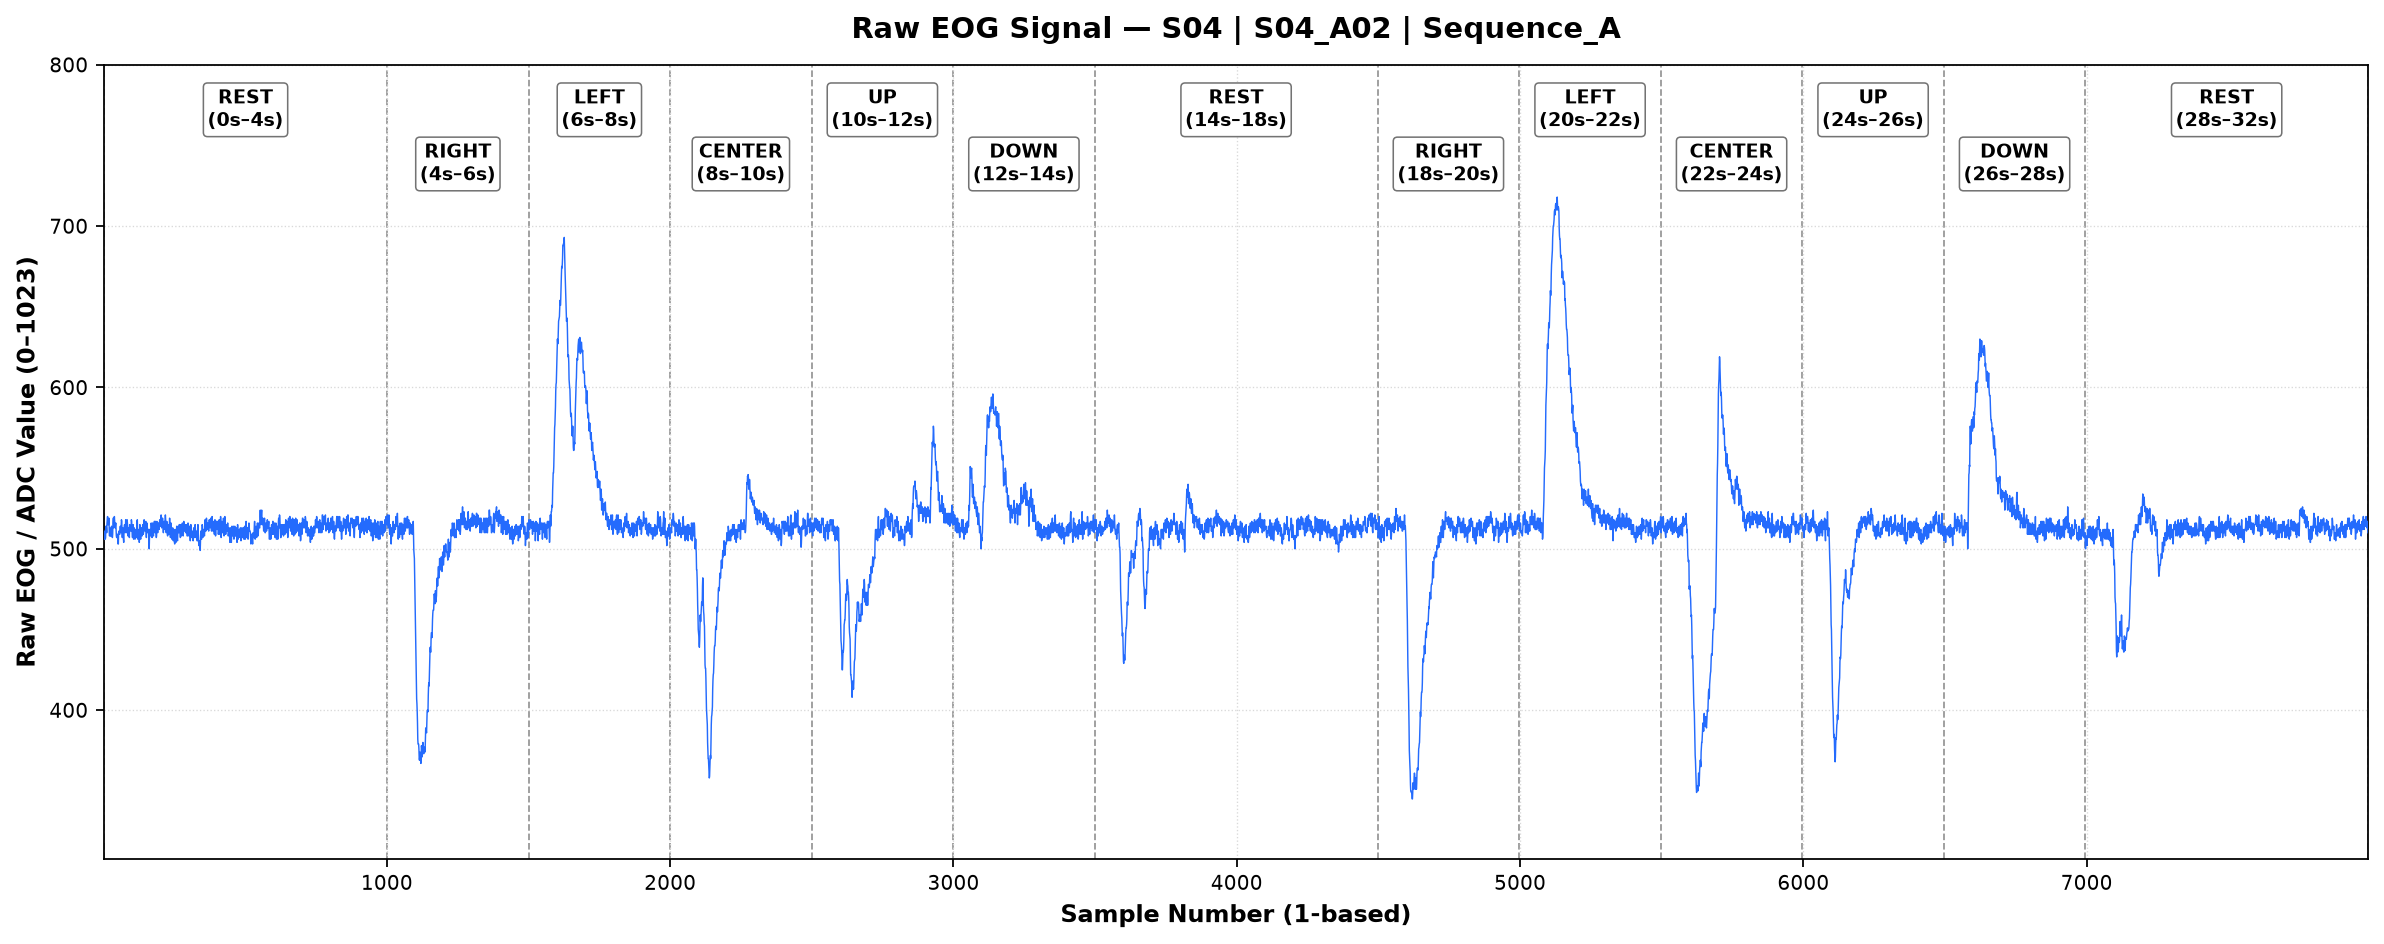


[OK] 32-SECOND MONOCHROME RAW EOG PLOT SAVED
  • Subject       : S04
  • Attempt       : S04_A02
  • Sequence      : Sequence_A
  • Samples       : 7993
  • Duration      : 31.997 s
  • Raw CSV       : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\S04_A02.csv
  • Raw Plot      : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\Plot_S04_A02.png

Stimulus timeline and sample boundaries:
   0.0s– 4.0s (sample     1– 1001): REST
   4.0s– 6.0s (sample  1001– 1500): RIGHT
   6.0s– 8.0s (sample  1500– 2000): LEFT
   8.0s–10.0s (sample  2000– 2499): CENTER
  10.0s–12.0s (sample  2499– 2999): UP
  12.0s–14.0s (sample  2999– 3498): DOWN
  14.0s–18.0s (sample  3498– 4497): REST
  18.0s–20.0s (sample  4497– 4997): RIGHT
  20.0s–22.0s (sample  4997– 5497): LEFT
  22.0s–24.0s (sample  5497– 5996): CENTER
  24.0s–26.0s (sample  5996– 6496): UP
  26.0s–28.0s (sample  6496– 6995): DOWN
  28.0s–32.0s (sample  6995– 7993): REST


127.0.0.1 - - [19/Oct/2026 23:58:39] "GET /api/status HTTP/1.1" 200 -


In [ ]:
# iSync — Cell 4: save raw attempt and plot the unsmoothed EOG signal
# Plot uses sample number, raw ADC values, monochrome styling, and the exact 36-second timeline.

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path, df_raw = save_raw_attempt(SUBJECT_ID, ATTEMPT_ID, raw_buffer)
data = pd.read_csv(csv_path)

print(f'Total samples: {len(data)}')
required_columns = ['Subject_ID', 'Attempt_ID', 'Sample_Index', 'Timestamp', 'EOG']
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f'Raw CSV is missing columns: {missing_columns}')

# Use the exact timeline that controlled acquisition, not a separately rebuilt schedule.
timeline = json.loads(json.dumps(engine.get_timeline()))
valid_timeline, timeline_message = validate_timeline(timeline)
if not valid_timeline:
    raise ValueError(f'Cannot plot an invalid stimulus timeline: {timeline_message}')

timeline_duration = float(timeline[-1]['end'])
if abs(timeline_duration - TARGET_DURATION) > 0.01:
    raise ValueError(f'Timeline duration = {timeline_duration}s. Expected {TARGET_DURATION}s.')

plot_raw_path = os.path.join(NEW_DATA_DIR, f'Plot_{ATTEMPT_ID}.png')
alt_png_path = os.path.join(NEW_DATA_DIR, f'{ATTEMPT_ID}.png')

sample_numbers = data['Sample_Index'].to_numpy(dtype=int)
timestamps = data['Timestamp'].to_numpy(dtype=float)
eog_raw = data['EOG'].to_numpy(dtype=float)
total_samples = len(data)

# Raw plot: blue unsmoothed EOG trace, no coloured phase spans, and no markers.
fig, ax = plt.subplots(figsize=(15, 6), dpi=160)
ax.plot(
    sample_numbers,
    eog_raw,
    color='#246BFD',
    linewidth=0.65,
    linestyle='-',
    antialiased=True,
    label='Raw EOG',
    zorder=3
)

y_min = float(np.min(eog_raw))
y_max = float(np.max(eog_raw))
y_range = max(y_max - y_min, 1.0)
ax.set_ylim(y_min - 0.10 * y_range, y_max + 0.22 * y_range)

# Convert every stimulus boundary in seconds to the nearest corresponding sample.
boundary_times = sorted(set(
    [0.0, TARGET_DURATION]
    + [float(p['start']) for p in timeline]
    + [float(p['end']) for p in timeline]
))
boundary_samples = {}
for boundary_t in boundary_times:
    idx = int(np.searchsorted(timestamps, boundary_t, side='left'))
    idx = min(max(idx, 0), total_samples - 1)
    boundary_samples[boundary_t] = int(sample_numbers[idx])

for boundary_t in boundary_times:
    boundary_idx = boundary_samples[boundary_t]
    ax.axvline(
        boundary_idx,
        color='0.55',
        linestyle='--',
        linewidth=0.8,
        alpha=0.9,
        zorder=1
    )

# Put RIGHT labels lower and LEFT labels higher, as in the reference layout.
# These are annotation positions only; the raw signal is never flipped or altered.
for i, phase in enumerate(timeline):
    start_t = float(phase['start'])
    end_t = float(phase['end'])
    label = str(phase['label']).upper()
    start_idx = boundary_samples[start_t]
    end_idx = boundary_samples[end_t]
    mid_idx = (start_idx + end_idx) / 2.0

    if label == 'LEFT':
        y_label = y_max + 0.145 * y_range
        va = 'center'
    elif label == 'RIGHT':
        y_label = y_max + 0.055 * y_range
        va = 'center'
    else:
        y_label = y_max + (0.145 if i % 2 == 0 else 0.055) * y_range
        va = 'center'

    ax.text(
        mid_idx,
        y_label,
        f'{label}\n({start_t:.0f}s–{end_t:.0f}s)',
        ha='center',
        va=va,
        fontsize=8.5,
        fontweight='bold',
        color='black',
        bbox=dict(
            boxstyle='round,pad=0.22',
            facecolor='white',
            edgecolor='0.45',
            linewidth=0.7
        ),
        zorder=5
    )

ax.set_xlim(1, max(total_samples, 2))
ax.set_xlabel('Sample Number (1-based)', fontsize=11, fontweight='bold')
ax.set_ylabel('Raw EOG / ADC Value (0–1023)', fontsize=11, fontweight='bold')
ax.set_title(
    f'Raw EOG Signal — {SUBJECT_ID} | {ATTEMPT_ID} | {SEQUENCE_ID}',
    fontsize=13,
    fontweight='bold',
    pad=12
)
ax.grid(True, color='0.85', linestyle=':', linewidth=0.6)
ax.tick_params(axis='both', labelsize=9)
plt.tight_layout()
fig.savefig(plot_raw_path, dpi=160, bbox_inches='tight')
fig.savefig(alt_png_path, dpi=160, bbox_inches='tight')
plt.show()

print()
print('=' * 65)
print('[OK] 36-SECOND MONOCHROME RAW EOG PLOT SAVED')
print('=' * 65)
print(f'  • Subject       : {SUBJECT_ID}')
print(f'  • Attempt       : {ATTEMPT_ID}')
print(f'  • Sequence      : {SEQUENCE_ID}')
print(f'  • Samples       : {len(data)}')
print(f'  • Duration      : {timestamps[-1]:.3f} s')
print(f'  • Raw CSV       : {csv_path}')
print(f'  • Raw Plot      : {plot_raw_path}')
print()
print('Stimulus timeline and sample boundaries:')
for phase in timeline:
    start_t = float(phase['start'])
    end_t = float(phase['end'])
    start_idx = boundary_samples[start_t]
    end_idx = boundary_samples[end_t]
    print(
        f"  {start_t:>4.1f}s–{end_t:>4.1f}s "
        f"(sample {start_idx:>5d}–{end_idx:>5d}): "
        f"{str(phase['label']).upper()}"
    )
print('=' * 65)


## 5. Robust EOG Signal Preprocessing

The preprocessing stage is intentionally conservative: it removes acquisition artifacts without artificially amplifying individual gesture phases.

1. **Validation + timestamp cleanup** — removes invalid/duplicate samples and sorts the timebase.
2. **Robust despiking** — detects isolated needle-like ADC/contact artifacts using a local median/MAD rule and replaces only those samples by interpolation.
3. **Shape-preserving resampling** — converts the Arduino stream to a uniform **250 Hz** grid using PCHIP interpolation, avoiding cubic overshoot.
4. **Zero-phase bandpass** — **0.10–10 Hz Butterworth** filter retains the main low-frequency EOG activity while rejecting baseline drift, mains interference and much high-frequency EMG/noise.
5. **Optional conservative wavelet denoising** — disabled by default because the band-limited signal is already strongly filtered.
6. **Robust normalization** — median/MAD scaling makes trials comparable without phase-specific gain.
7. **Quality control** — reports artifact rate, ADC rail hits, duration and sampling rate and saves both diagnostic and final plots.

**Important:** Adaptive per-phase gain has been removed. The preprocessing stage must not make one gesture artificially larger than another. Raw recordings remain untouched, while the final curated dataset uses the robust-normalized EOG signal.

iSync — ROBUST EOG PREPROCESSING
Raw file             : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\S04_A02.csv
Raw samples          : 7,986
Recording duration   : 31.997 s
Raw sampling rate    : 249.56 Hz
Processing rate      : 250 Hz

PIPELINE
  1. Validate + sort timestamps
  2. Robust transient-artifact/despike correction
  3. Shape-preserving resampling to 250 Hz
  4. Zero-phase Butterworth bandpass 0.10–10.0 Hz
  5. Wavelet denoising : None
  6. Robust median/MAD normalization

QUALITY
  Artifact samples corrected : 17 (0.21%)
  ADC near 0               : 0
  ADC near 1023            : 0
  Normalized values clipped: 1,032
[OK] Low transient-artifact rate.


127.0.0.1 - - [19/Oct/2026 23:58:39] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:39] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:39] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:40] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:41] "GET /api/status HTTP/1.1" 200 -


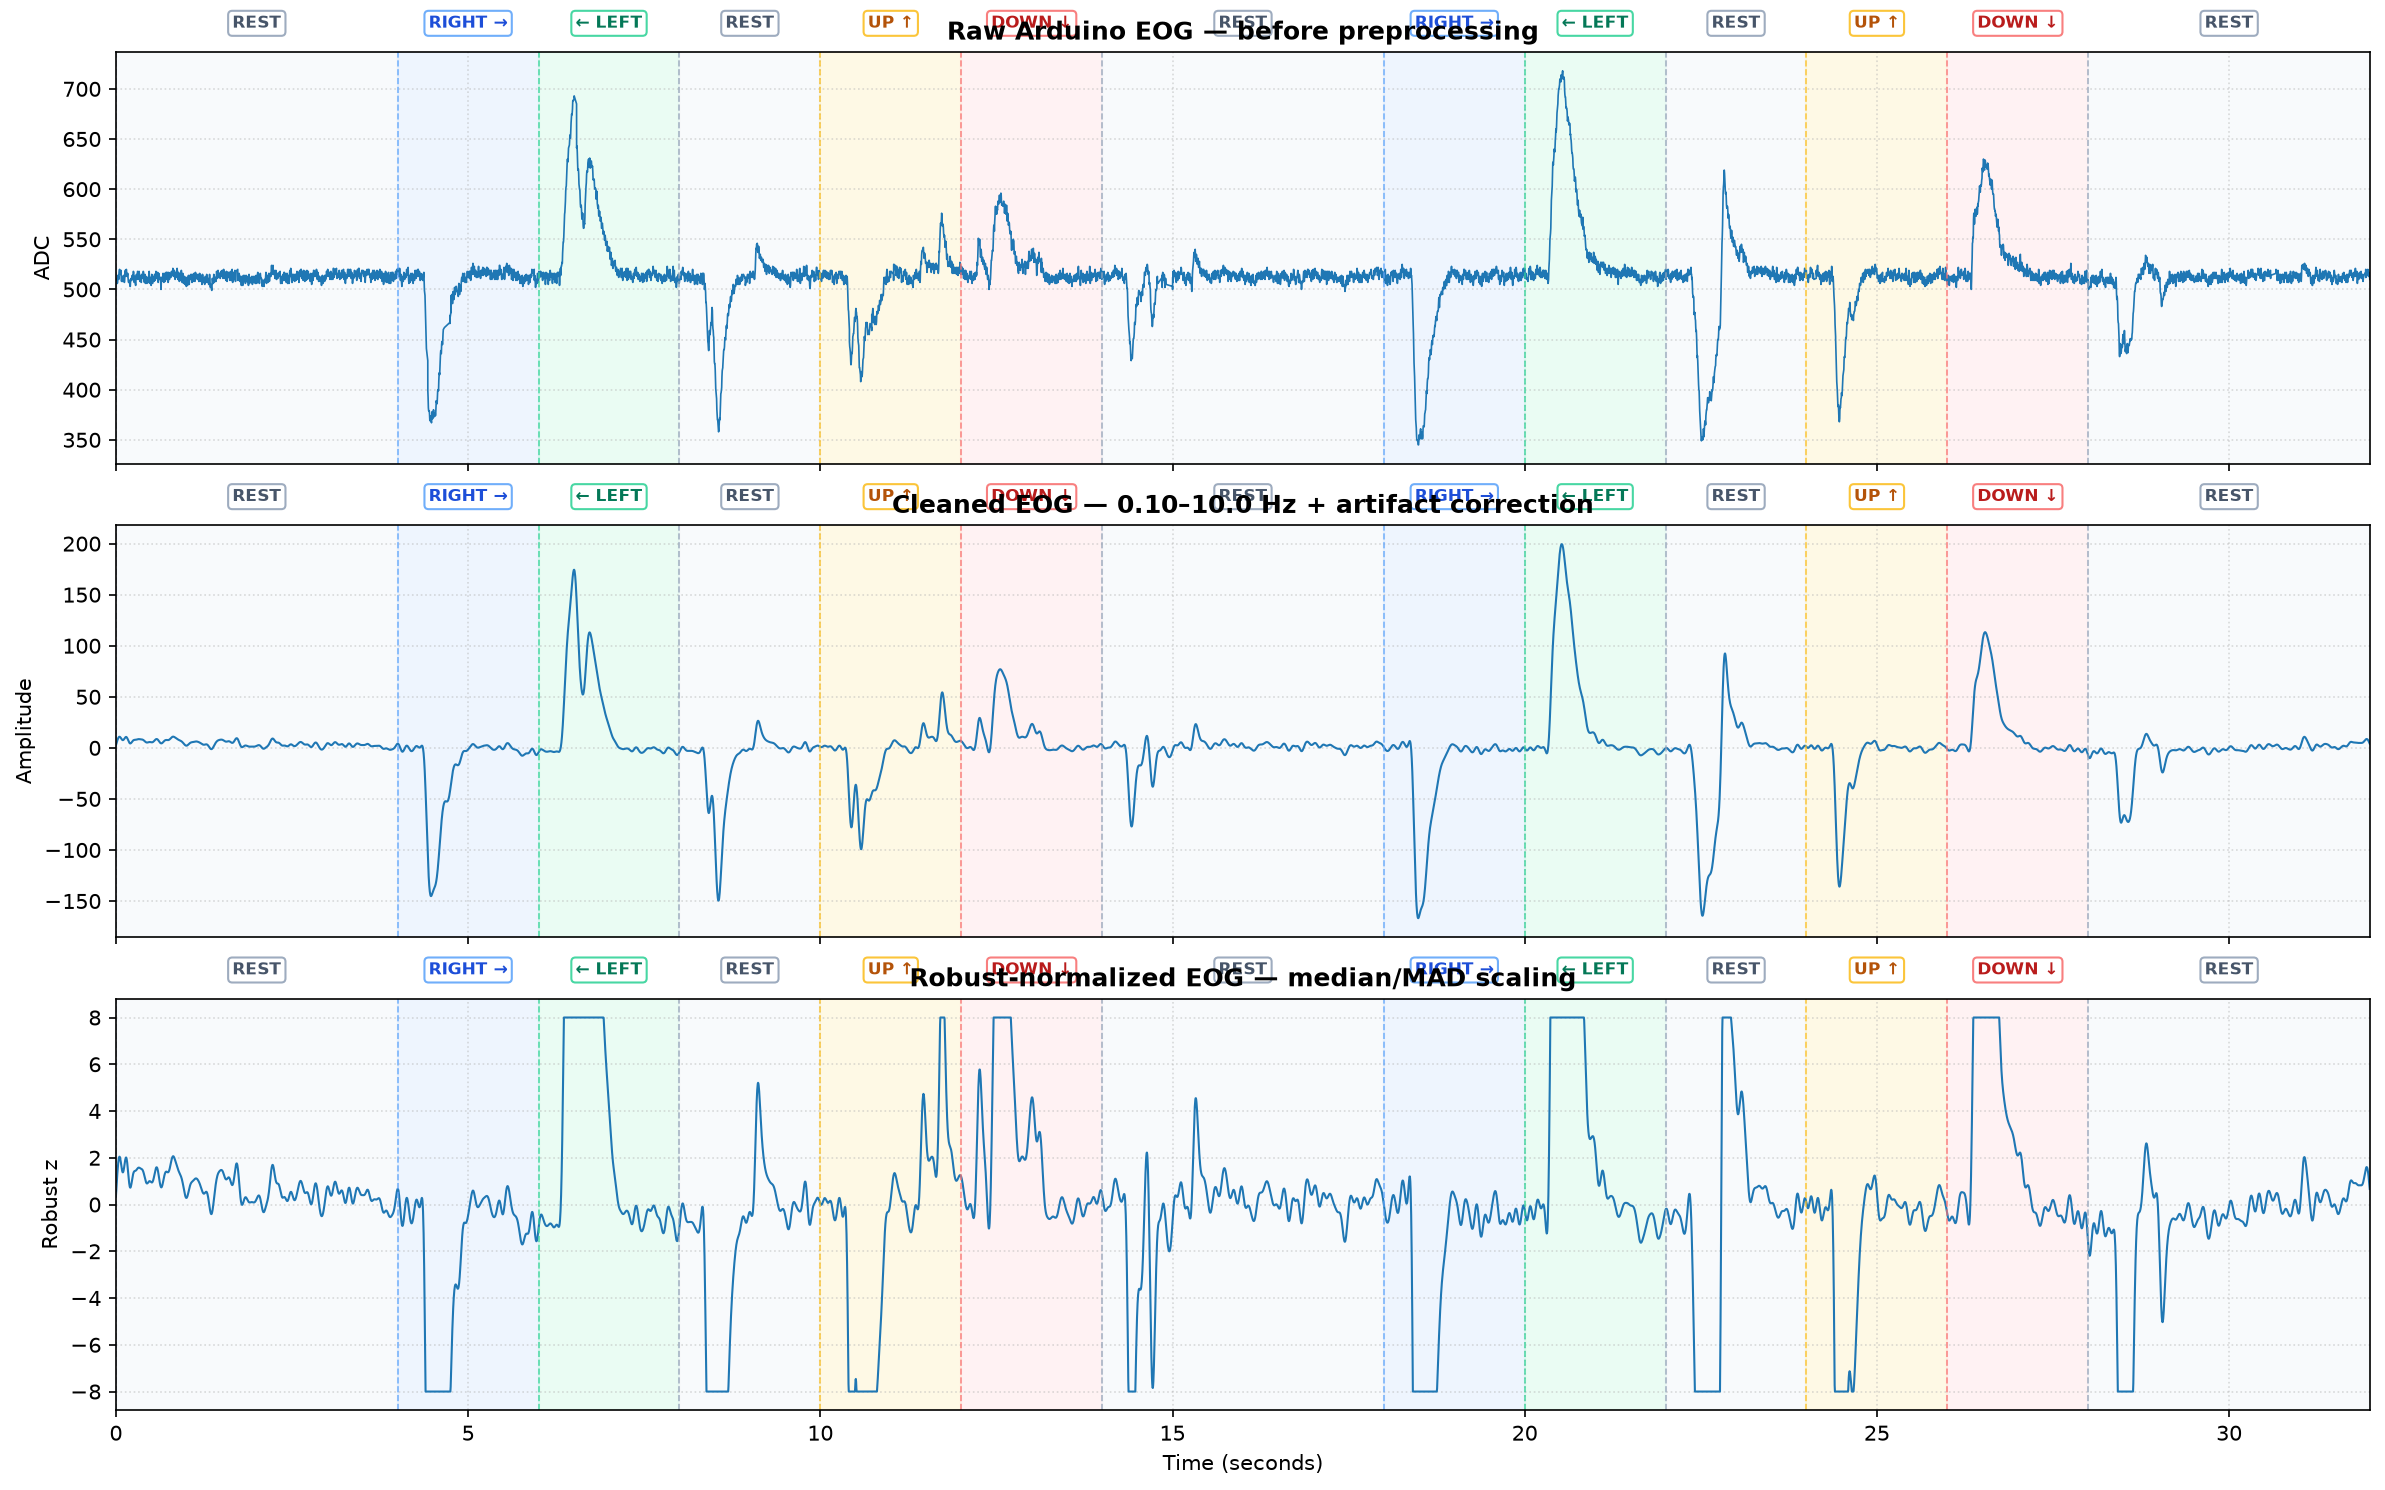

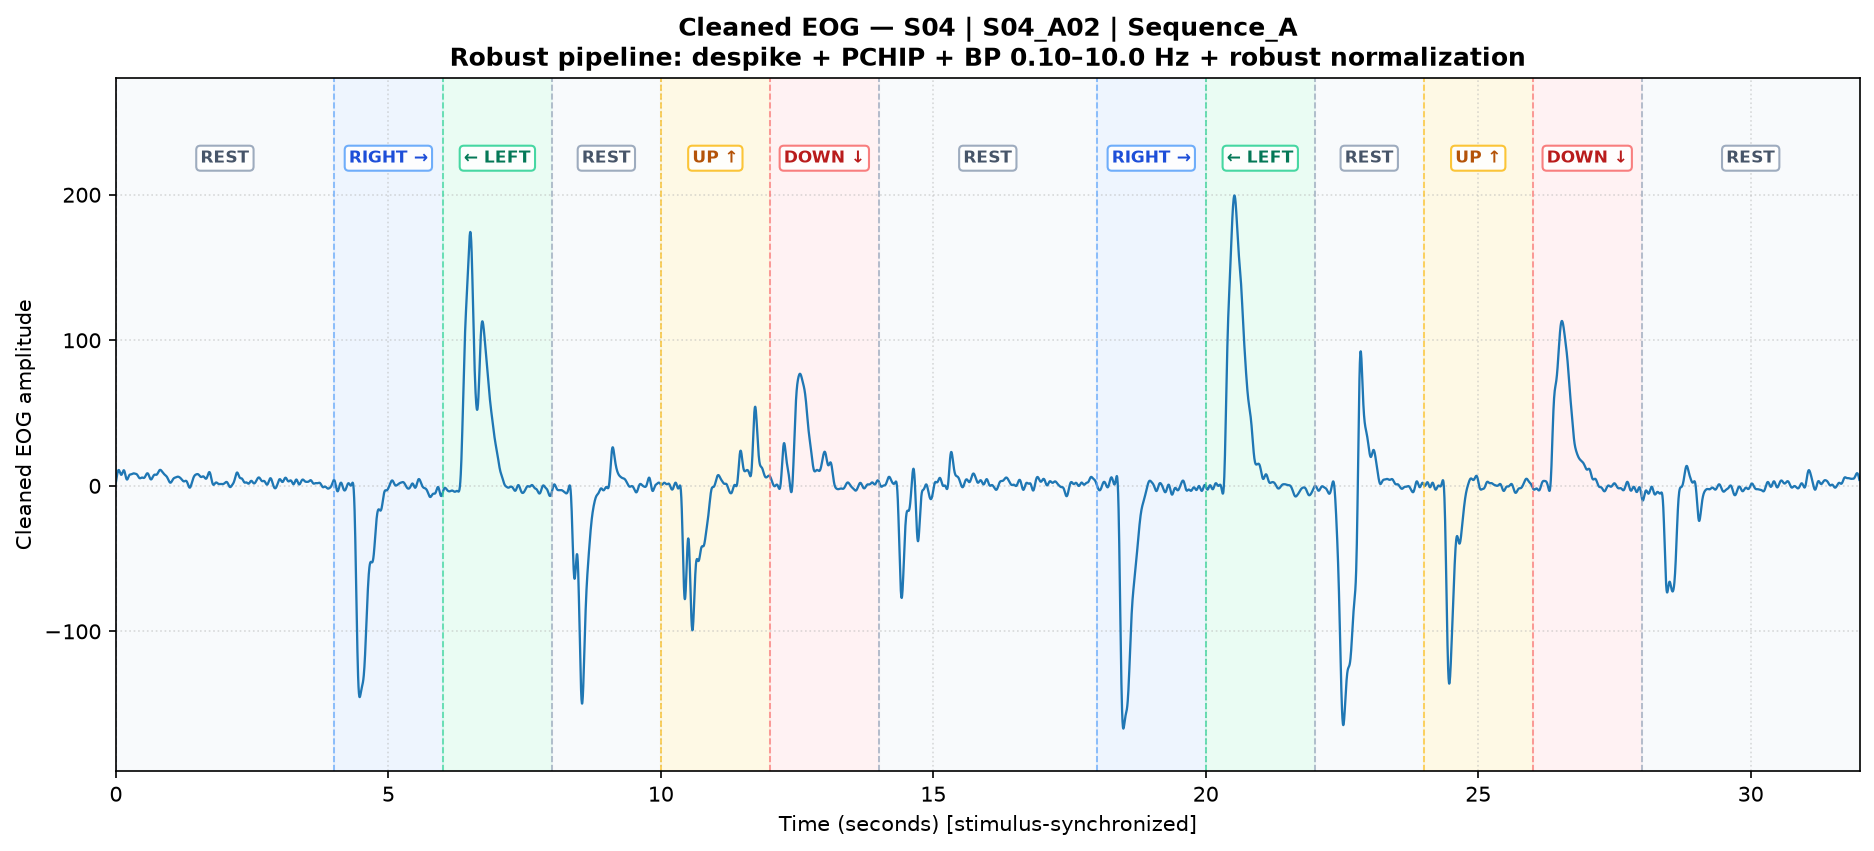


[OK] PREPROCESSING COMPLETE
[OK] Cleaned CSV      : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\Processed Data\S04_A02_processed.csv
[OK] Diagnostic plot  : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\Diag_S04_A02.png
[OK] Final plot       : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\New Data Plots\SP_S04_A02.png
[OK] Raw CSV remains untouched.


In [ ]:
# iSync — Robust EOG preprocessing and quality control

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.signal import butter, sosfiltfilt, medfilt
try:
    import pywt
    HAS_PYWT = True
except ImportError:
    pywt = None
    HAS_PYWT = False

# -----------------------------
# Configuration
# -----------------------------
TARGET_FS = 250.0
LOWCUT_HZ = 0.10
HIGHCUT_HZ = 10.0
DESPIKE_WINDOW_SEC = 0.12
DESPIKE_THRESHOLD = 6.0
DESPIKE_MIN_DEVIATION = 20.0
USE_WAVELET = False          # Keep False by default; band-limited EOG is already denoised.
WAVELET = 'sym4'
WAVELET_LEVEL = 3
NORMALIZE_EOG = True
ROBUST_CLIP = 8.0

CURRENT_DIR = os.path.abspath(os.getcwd())
if 'csv_path' in globals() and os.path.exists(csv_path):
    # Raw attempts live in <project>/New Data Plots/.
    BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath(csv_path)))
elif os.path.basename(CURRENT_DIR).lower() == 'demo':
    BASE_DIR = os.path.dirname(CURRENT_DIR)
else:
    BASE_DIR = CURRENT_DIR

NEW_DATA_DIR = os.path.join(BASE_DIR, 'New Data Plots')
PROCESSED_DATA_DIR = os.path.join(BASE_DIR, 'Processed Data')
os.makedirs(NEW_DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

# -----------------------------
# Locate the raw recording
# -----------------------------
if 'csv_path' not in globals() or not os.path.exists(csv_path):
    candidates = sorted(
        glob.glob(os.path.join(NEW_DATA_DIR, 'S*_A*.csv')),
        key=os.path.getmtime
    )
    if not candidates:
        raise FileNotFoundError(f'No raw EOG attempt CSV found in:\n{NEW_DATA_DIR}')
    csv_path = candidates[-1]

data = pd.read_csv(csv_path)
required = {'Timestamp', 'EOG'}
missing = required - set(data.columns)
if missing:
    raise ValueError(f'Raw recording is missing required columns: {sorted(missing)}')

time_raw = pd.to_numeric(data['Timestamp'], errors='coerce').to_numpy(dtype=float)
signal_raw = pd.to_numeric(data['EOG'], errors='coerce').to_numpy(dtype=float)

valid = np.isfinite(time_raw) & np.isfinite(signal_raw)
if valid.sum() < 100:
    raise ValueError(f'Only {valid.sum()} valid EOG samples are available.')

time_raw = time_raw[valid]
signal_raw = signal_raw[valid]

# Sort and remove duplicate timestamps before interpolation.
order = np.argsort(time_raw, kind='mergesort')
time_raw = time_raw[order]
signal_raw = signal_raw[order]

unique_time, inverse = np.unique(time_raw, return_inverse=True)
if len(unique_time) != len(time_raw):
    signal_raw = np.bincount(inverse, weights=signal_raw) / np.bincount(inverse)
    time_raw = unique_time

time_raw -= time_raw[0]
duration = float(time_raw[-1])
if duration < 10:
    raise ValueError(f'Recording is only {duration:.2f}s long; the 36s iSync protocol was not completed.')

raw_fs = (len(signal_raw) - 1) / duration
if raw_fs < 100:
    raise ValueError(f'Raw sampling rate is too low ({raw_fs:.1f} Hz). Expected approximately 250 Hz.')

# -----------------------------
# Stage 1 — Robust despiking
# -----------------------------
# A genuine eye movement is sustained over many samples. A one/few-sample
# needle is therefore treated as an acquisition/contact artifact.
window = max(5, int(round(DESPIKE_WINDOW_SEC * raw_fs)))
if window % 2 == 0:
    window += 1

local_median = pd.Series(signal_raw).rolling(
    window=window, center=True, min_periods=1
).median().to_numpy()

abs_residual = np.abs(signal_raw - local_median)
local_mad = pd.Series(abs_residual).rolling(
    window=window, center=True, min_periods=1
).median().to_numpy()

robust_sigma = 1.4826 * local_mad
threshold = np.maximum(DESPIKE_MIN_DEVIATION, DESPIKE_THRESHOLD * robust_sigma)
spike_mask = abs_residual > threshold

# Do not replace long sustained regions: only isolated/transient outliers.
spike_mask = spike_mask & (
    pd.Series(spike_mask).rolling(window=5, center=True, min_periods=1).sum().to_numpy() <= 3
)

# Isolated ADC rail hits are also acquisition artifacts.
rail_mask = (signal_raw <= 1) | (signal_raw >= 1022)
rail_mask = rail_mask & (
    pd.Series(rail_mask).rolling(window=5, center=True, min_periods=1).sum().to_numpy() <= 3
)
artifact_mask = spike_mask | rail_mask

signal_despiked = signal_raw.copy()
if artifact_mask.any():
    good = ~artifact_mask
    if good.sum() < 20:
        raise ValueError('Too many samples were flagged as artifacts; raw acquisition should be checked.')
    signal_despiked[artifact_mask] = np.interp(
        time_raw[artifact_mask],
        time_raw[good],
        signal_raw[good]
    )

# -----------------------------
# Stage 2 — Uniform resampling
# -----------------------------
t_uniform = np.arange(0.0, duration + 0.5 / TARGET_FS, 1.0 / TARGET_FS)
t_uniform = t_uniform[t_uniform <= duration + 1e-9]

# PCHIP is shape-preserving and avoids the overshoot that cubic interpolation
# can create around sharp artifacts.
resampler = PchipInterpolator(time_raw, signal_despiked, extrapolate=False)
eog_resampled = resampler(t_uniform)
finite = np.isfinite(eog_resampled)
if not finite.all():
    eog_resampled = np.interp(t_uniform, t_uniform[finite], eog_resampled[finite])

fs = TARGET_FS

# -----------------------------
# Stage 3 — Zero-phase EOG bandpass
# -----------------------------
# EOG is dominated by low-frequency ocular activity. 0.10–10 Hz removes
# baseline drift, mains/high-frequency noise and much of the EMG component.
sos = butter(
    4,
    [LOWCUT_HZ, HIGHCUT_HZ],
    btype='bandpass',
    fs=fs,
    output='sos'
)
eog_bandpass = sosfiltfilt(sos, eog_resampled)

# A 50/100 Hz notch is intentionally not applied: the 10 Hz low-pass already
# rejects those frequencies, so an extra notch would be redundant.

# -----------------------------
# Stage 4 — Optional conservative wavelet denoising
# -----------------------------
eog_denoised = eog_bandpass.copy()
wavelet_used = 'None'
if USE_WAVELET:
    if not HAS_PYWT:
        print('[WARNING] USE_WAVELET=True but PyWavelets is unavailable; skipping wavelet stage.')
    else:
        max_level = pywt.swt_max_level(len(eog_denoised))
        level = min(WAVELET_LEVEL, max_level)
        if level >= 1:
            pad = (-len(eog_denoised)) % (2 ** level)
            padded = np.pad(eog_denoised, (0, pad), mode='reflect') if pad else eog_denoised.copy()
            coeffs = pywt.swt(padded, WAVELET, level=level)
            sigma = np.median(np.abs(coeffs[-1][1])) / 0.6745
            threshold_w = sigma * np.sqrt(2.0 * np.log(len(padded)))
            coeffs_clean = [
                (cA, pywt.threshold(cD, threshold_w, mode='soft'))
                for cA, cD in coeffs
            ]
            eog_denoised = pywt.iswt(coeffs_clean, WAVELET)[:len(eog_denoised)]
            wavelet_used = f'{WAVELET}, level {level}'

# -----------------------------
# Stage 5 — Robust normalization
# -----------------------------
robust_center = float(np.median(eog_denoised))
mad = float(np.median(np.abs(eog_denoised - robust_center)))
robust_scale = 1.4826 * mad

if robust_scale < 1e-9:
    raise ValueError('Robust signal scale is essentially zero; the EOG recording is not usable.')

if NORMALIZE_EOG:
    eog_normalized = (eog_denoised - robust_center) / robust_scale
else:
    eog_normalized = eog_denoised.copy()

# A very large residual is almost certainly an acquisition artifact. Limit only
# the normalized representation; the cleaned physical-amplitude signal is kept.
clip_count = int(np.sum(np.abs(eog_normalized) > ROBUST_CLIP))
if NORMALIZE_EOG:
    eog_normalized = np.clip(eog_normalized, -ROBUST_CLIP, ROBUST_CLIP)

# -----------------------------
# Quality metrics
# -----------------------------
clip_low = int(np.sum(signal_raw <= 1))
clip_high = int(np.sum(signal_raw >= 1022))
artifact_percent = 100.0 * artifact_mask.mean()

print('=' * 78)
print('iSync — ROBUST EOG PREPROCESSING')
print('=' * 78)
print(f'Raw file             : {csv_path}')
print(f'Raw samples          : {len(signal_raw):,}')
print(f'Recording duration   : {duration:.3f} s')
print(f'Raw sampling rate    : {raw_fs:.2f} Hz')
print(f'Processing rate      : {fs:.0f} Hz')
print()
print('PIPELINE')
print('  1. Validate + sort timestamps')
print('  2. Robust transient-artifact/despike correction')
print('  3. Shape-preserving resampling to 250 Hz')
print(f'  4. Zero-phase Butterworth bandpass {LOWCUT_HZ:.2f}–{HIGHCUT_HZ:.1f} Hz')
print(f'  5. Wavelet denoising : {wavelet_used}')
print('  6. Robust median/MAD normalization')
print()
print('QUALITY')
print(f'  Artifact samples corrected : {spike_mask.sum():,} ({artifact_percent:.2f}%)')
print(f'  ADC near 0               : {clip_low:,}')
print(f'  ADC near 1023            : {clip_high:,}')
print(f'  Normalized values clipped: {clip_count:,}')
print('=' * 78)

if artifact_percent > 5.0:
    print('[WARNING] >5% of samples were flagged as transient artifacts. Check electrodes/cables before collecting the next subject.')
elif artifact_percent > 1.0:
    print('[CHECK] Some transient artifacts were corrected; this is acceptable for inspection.')
else:
    print('[OK] Low transient-artifact rate.')

# -----------------------------
# Build processed dataframe
# -----------------------------
# Keep the exact stimulus timebase. Labels are assigned later from the
# authoritative iSync timeline.
df_processed = pd.DataFrame({
    'Timestamp': t_uniform,
    'EOG': eog_denoised,
    'EOG_Normalized': eog_normalized
})

processed_csv_path = os.path.join(
    PROCESSED_DATA_DIR,
    f'{os.path.splitext(os.path.basename(csv_path))[0]}_processed.csv'
)
df_processed.to_csv(processed_csv_path, index=False)

# -----------------------------
# Diagnostic plot
# -----------------------------
timeline = SEQUENCES[SEQUENCE_ID]['timeline'] if SEQUENCE_ID in SEQUENCES else get_sequence_timeline(SEQUENCE_ID)

PHASE_STYLES = {
    'REST':  ('#f1f5f9', '#94a3b8', '#475569', 'REST'),
    'RIGHT': ('#dbeafe', '#60a5fa', '#1d4ed8', 'RIGHT →'),
    'LEFT':  ('#d1fae5', '#34d399', '#047857', '← LEFT'),
    'UP':    ('#fef3c7', '#fbbf24', '#b45309', 'UP ↑'),
    'DOWN':  ('#ffe4e6', '#f87171', '#b91c1c', 'DOWN ↓')
}

def add_phase_overlay(ax, y_min, y_max):
    span = max(y_max - y_min, 1.0)
    for phase in timeline:
        label = str(phase['label']).upper()
        bg, border, text, icon = PHASE_STYLES.get(label, PHASE_STYLES['REST'])
        start, end = float(phase['start']), float(phase['end'])
        ax.axvspan(start, end, color=bg, alpha=0.45, zorder=0)
        ax.axvline(start, color=border, linestyle='--', linewidth=0.8, alpha=0.8)
        ax.text(
            (start + end) / 2, y_max + 0.07 * span,
            icon, ha='center', va='center',
            fontsize=8, fontweight='bold', color=text,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                      edgecolor=border, linewidth=1, alpha=0.9)
        )

fig, axes = plt.subplots(3, 1, figsize=(16, 10), dpi=150, sharex=True)

axes[0].plot(time_raw, signal_raw, linewidth=0.8)
axes[0].set_title('Raw Arduino EOG — before preprocessing', fontweight='bold')
axes[0].set_ylabel('ADC')

axes[1].plot(t_uniform, eog_denoised, linewidth=1.0)
axes[1].set_title(f'Cleaned EOG — {LOWCUT_HZ:.2f}–{HIGHCUT_HZ:.1f} Hz + artifact correction', fontweight='bold')
axes[1].set_ylabel('Amplitude')

axes[2].plot(t_uniform, eog_normalized, linewidth=1.0)
axes[2].set_title('Robust-normalized EOG — median/MAD scaling', fontweight='bold')
axes[2].set_ylabel('Robust z')
axes[2].set_xlabel('Time (seconds)')

for ax in axes:
    ymin, ymax = ax.get_ylim()
    add_phase_overlay(ax, ymin, ymax)
    ax.set_xlim(0, max(TARGET_DURATION, duration))
    ax.grid(True, linestyle=':', alpha=0.45)

plt.tight_layout()

plot_diag_path = os.path.join(NEW_DATA_DIR, f'Diag_{ATTEMPT_ID}.png')
fig.savefig(plot_diag_path, dpi=150, bbox_inches='tight')
plt.show()

# -----------------------------
# Final cleaned plot
# -----------------------------
fig, ax = plt.subplots(figsize=(15, 6), dpi=150)
ax.plot(t_uniform, eog_denoised, linewidth=1.1)

ymin, ymax = float(np.min(eog_denoised)), float(np.max(eog_denoised))
span = max(ymax - ymin, 1.0)
ax.set_ylim(ymin - 0.08 * span, ymax + 0.22 * span)
add_phase_overlay(ax, ymin, ymax)
ax.set_xlim(0, max(TARGET_DURATION, duration))
ax.set_xlabel('Time (seconds) [stimulus-synchronized]')
ax.set_ylabel('Cleaned EOG amplitude')
ax.set_title(
    f'Cleaned EOG — {SUBJECT_ID} | {ATTEMPT_ID} | {SEQUENCE_ID}\n'
    f'Robust pipeline: despike + PCHIP + BP {LOWCUT_HZ:.2f}–{HIGHCUT_HZ:.1f} Hz + robust normalization',
    fontweight='bold'
)
ax.grid(True, linestyle=':', alpha=0.45)

plot_sp_path = os.path.join(NEW_DATA_DIR, f'SP_{ATTEMPT_ID}.png')
fig.savefig(plot_sp_path, dpi=150, bbox_inches='tight')
plt.show()

print()
print('=' * 78)
print('[OK] PREPROCESSING COMPLETE')
print(f'[OK] Cleaned CSV      : {processed_csv_path}')
print(f'[OK] Diagnostic plot  : {plot_diag_path}')
print(f'[OK] Final plot       : {plot_sp_path}')
print('[OK] Raw CSV remains untouched.')
print('=' * 78)


## 6. Quality Decision & Dataset Curation

Review the raw/cleaned diagnostic plots before selecting the attempt.

- `SELECT`: assigns the authoritative iSync timeline labels and stores the **robust-normalized cleaned EOG** in `LabelData/Eog Data.csv`.
- `REJECT`: keeps the raw attempt and processing outputs archived for traceability; it is not added to the final dataset.
- `RECORD_AGAIN`: keeps the current attempt archived and allows a fresh acquisition.

In [ ]:
# iSync — optimized code cell 12

DECISION = 'SELECT'
REPLACE_IF_EXISTS = True

def get_exact_trial_timeline():
    timeline = None
    try:
        timeline = engine.get_timeline()
    except Exception:
        timeline = None
    if not timeline:
        timeline = SEQUENCES[SEQUENCE_ID]['timeline']
    timeline = json.loads(json.dumps(timeline))
    for phase in timeline:
        label = str(phase.get('label', 'REST')).upper().strip()
        phase['label'] = label
        phase['label'] = label
    return timeline

def assign_labels(df, timeline):
    dfl = df.copy()

    def get_lbl(t):
        try:
            t = float(t)
        except Exception:
            return 'REST'
        for phase in timeline:
            start = float(phase['start'])
            end = float(phase['end'])
            if start <= t < end:
                label = str(phase.get('label', 'REST')).upper().strip()
                return label
                return label
        return 'REST'
    dfl['Label'] = dfl['Timestamp'].apply(get_lbl)
    return dfl

def recording_to_wide_block(df_recording, subject_id):
    subject_id = normalize_subject_id(subject_id)
    df_recording = df_recording.copy().reset_index(drop=True)
    required = ['Timestamp', 'EOG', 'Label']
    missing = [col for col in required if col not in df_recording.columns]
    if missing:
        raise ValueError(f'❌ Missing columns in recording: {missing}')
    sample_index = np.arange(1, len(df_recording) + 1)
    wide_block = pd.DataFrame({'Sample_Index': sample_index, f'{subject_id}_Timestamp': pd.to_numeric(df_recording['Timestamp'], errors='coerce').values, f'{subject_id}_EOG': pd.to_numeric(df_recording['EOG'], errors='coerce').values, f'{subject_id}_Label': df_recording['Label'].astype(str).str.strip().str.upper().replace('CENTER', 'REST').values})
    return wide_block

def convert_long_master_to_wide(df_master):
    old_required = {'Subject_ID', 'Timestamp', 'EOG', 'Label'}
    if not old_required.issubset(set(df_master.columns)):
        return df_master
    if 'Sample_Index' in df_master.columns and any((str(c).endswith('_Timestamp') for c in df_master.columns)):
        return df_master
    print('⚠ Existing final CSV is old long format.')
    print('  Converting existing master to wide format...')
    df_master = df_master.copy()
    df_master['Subject_ID'] = df_master['Subject_ID'].astype(str).str.strip()
    subject_blocks = []
    subjects_existing = df_master['Subject_ID'].dropna().drop_duplicates().tolist()
    for subject in subjects_existing:
        sdf = df_master[df_master['Subject_ID'] == subject].copy()
        sdf = sdf.reset_index(drop=True)
        block = recording_to_wide_block(sdf, subject)
        subject_blocks.append(block)
    if not subject_blocks:
        return pd.DataFrame(columns=['Sample_Index'])
    master_wide = subject_blocks[0]
    for block in subject_blocks[1:]:
        master_wide = pd.merge(master_wide, block, on='Sample_Index', how='outer')
    master_wide = master_wide.sort_values('Sample_Index').reset_index(drop=True)
    master_wide['Sample_Index'] = np.arange(1, len(master_wide) + 1)
    return master_wide
has_sel, existing_att = check_subject_in_final_dataset(SUBJECT_ID)
print('=' * 78)
print(' RECORDING DECISION ')
print('=' * 78)
print(f'Subject       : {SUBJECT_ID}')
print(f'Attempt       : {ATTEMPT_ID}')
print(f'Sequence      : {SEQUENCE_ID}')
print(f'Decision      : {DECISION}')
print(f"Existing selected: {(existing_att if has_sel else 'None')}")
print('=' * 78)
trial_timeline = get_exact_trial_timeline()
print('[OK] Exact trial timeline loaded.')
print(f'[OK] Timeline phases: {len(trial_timeline)}')
if DECISION == 'SELECT':
    if has_sel and (not REPLACE_IF_EXISTS):
        print()
        print(f'⚠ [BLOCKED] Subject {SUBJECT_ID} already has a selected recording.')
        print(f'Existing attempt: {existing_att}')
        print('Set REPLACE_IF_EXISTS = True if you intentionally want to replace it.')
    else:
        # The final dataset must contain the validated, cleaned EOG signal.
        # Raw data remains archived separately in New Data/.
        if 'df_processed' not in globals():
            raise RuntimeError(
                'Cleaned EOG data is not available. Run the preprocessing cell before selecting this trial.'
            )
        processed_source = df_processed[['Timestamp', 'EOG_Normalized']].copy()
        processed_source = processed_source.rename(columns={'EOG_Normalized': 'EOG'})
        df_labeled = assign_labels(processed_source, trial_timeline)
        df_new_wide = recording_to_wide_block(df_labeled, SUBJECT_ID)
        print()
        print('[OK] Cleaned/normalized recording converted to wide subject block.')
        print(f'[OK] Columns: {list(df_new_wide.columns)}')
        if os.path.exists(FINAL_CSV_PATH):
            df_master = pd.read_csv(FINAL_CSV_PATH)
            df_master = convert_long_master_to_wide(df_master)
        else:
            df_master = pd.DataFrame(columns=['Sample_Index'])
        if not df_master.empty and 'Sample_Index' in df_master.columns:
            subject_columns = [f'{SUBJECT_ID}_Timestamp', f'{SUBJECT_ID}_EOG', f'{SUBJECT_ID}_Label']
            existing_subject_columns = [col for col in subject_columns if col in df_master.columns]
            if existing_subject_columns:
                if REPLACE_IF_EXISTS:
                    print()
                    print(f'[Curator] Replacing previous selected recording for {SUBJECT_ID}...')
                    df_master = df_master.drop(columns=existing_subject_columns)
                else:
                    raise ValueError(f'❌ Subject {SUBJECT_ID} already exists in final dataset.')
        if df_master.empty:
            df_combined = df_new_wide.copy()
        else:
            df_combined = pd.merge(df_master, df_new_wide, on='Sample_Index', how='outer')
        df_combined = df_combined.sort_values('Sample_Index').reset_index(drop=True)
        df_combined['Sample_Index'] = np.arange(1, len(df_combined) + 1)
        all_subjects = set()
        for col in df_combined.columns:
            col = str(col)
            if col.endswith('_Timestamp'):
                all_subjects.add(col.replace('_Timestamp', ''))

        def subject_sort_key(subject):
            subject = str(subject)
            if subject.startswith('S') and subject[1:].isdigit():
                return (0, int(subject[1:]))
            return (1, subject)
        all_subjects = sorted(all_subjects, key=subject_sort_key)
        ordered_columns = ['Sample_Index']
        for subject in all_subjects:
            ordered_columns.extend([f'{subject}_Timestamp', f'{subject}_EOG', f'{subject}_Label'])
        df_combined = df_combined[ordered_columns]
        df_combined.to_csv(FINAL_CSV_PATH, index=False)
        rec = pd.DataFrame([{'Subject_ID': SUBJECT_ID, 'Attempt_ID': ATTEMPT_ID, 'Sequence_ID': SEQUENCE_ID, 'Status': 'SELECTED', 'Sample_Count': len(df_new_wide), 'Duration': round(actual_dur, 3), 'Sampling_Rate': round(TARGET_FS, 1), 'Selected': True, 'Recording_DateTime': datetime.now().strftime('%Y-%m-%d %H:%M:%S')}])
        metadata_exists = os.path.exists(METADATA_CSV_PATH)
        rec.to_csv(METADATA_CSV_PATH, mode='a' if metadata_exists else 'w', header=not metadata_exists, index=False)
        print()
        print('=' * 78)
        print('[OK] [SUCCESS] Recording selected!')
        print('=' * 78)
        print(f'Subject       : {SUBJECT_ID}')
        print(f'Attempt       : {ATTEMPT_ID}')
        print(f'Sequence      : {SEQUENCE_ID}')
        print(f'Samples       : {len(df_new_wide)}')
        print(f'Duration      : {actual_dur:.3f} s')
        print(f'Estimated Fs  : {est_fs:.1f} Hz')
        print()
        print(f'[OK] Final dataset:')
        print(f'     {FINAL_CSV_PATH}')
        print()
        print('[OK] Final format:')
        print('     Sample_Index + Timestamp/normalized-EOG/Label per subject')
        print()
        print('[OK] Attempt_ID is NOT stored in final CSV.')
        print('[OK] Attempt_ID remains in raw/metadata for traceability.')
        print('=' * 78)
elif DECISION in ['REJECT', 'RECORD_AGAIN']:
    status_value = 'REJECTED' if DECISION == 'REJECT' else 'RECORD_AGAIN'
    rec = pd.DataFrame([{'Subject_ID': SUBJECT_ID, 'Attempt_ID': ATTEMPT_ID, 'Sequence_ID': SEQUENCE_ID, 'Status': status_value, 'Sample_Count': len(df_new_wide), 'Duration': round(actual_dur, 3), 'Sampling_Rate': round(TARGET_FS, 1), 'Selected': False, 'Recording_DateTime': datetime.now().strftime('%Y-%m-%d %H:%M:%S')}])
    metadata_exists = os.path.exists(METADATA_CSV_PATH)
    rec.to_csv(METADATA_CSV_PATH, mode='a' if metadata_exists else 'w', header=not metadata_exists, index=False)
    print()
    print('=' * 78)
    if DECISION == 'REJECT':
        print(f'❌ [REJECTED] Attempt {ATTEMPT_ID}')
        print('Recording remains safely archived in New Data/.')
    else:
        print(f'🔄 [RECORD AGAIN] Attempt {ATTEMPT_ID}')
        print('Recording remains archived in New Data/.')
        print('A new attempt should be recorded.')
    print('=' * 78)
else:
    raise ValueError(f"❌ Invalid DECISION: {DECISION}\nAllowed values: 'SELECT', 'REJECT', 'RECORD_AGAIN'")

 RECORDING DECISION 
Subject       : S04
Attempt       : S04_A02
Sequence      : Sequence_A
Decision      : SELECT
Existing selected: S04
[OK] Exact trial timeline loaded.
[OK] Timeline phases: 13

[OK] Cleaned/normalized recording converted to wide subject block.
[OK] Columns: ['Sample_Index', 'S04_Timestamp', 'S04_EOG', 'S04_Label']

[Curator] Replacing previous selected recording for S04...

[OK] [SUCCESS] Recording selected!
Subject       : S04
Attempt       : S04_A02
Sequence      : Sequence_A
Samples       : 8000
Duration      : 31.997 s
Estimated Fs  : 249.8 Hz

[OK] Final dataset:
     c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\LabelData\Eog Data.csv

[OK] Final format:
     Sample_Index + Timestamp/normalized-EOG/Label per subject

[OK] Attempt_ID is NOT stored in final CSV.
[OK] Attempt_ID remains in raw/metadata for traceability.


127.0.0.1 - - [19/Oct/2026 23:58:43] "GET /api/status HTTP/1.1" 200 -


## 7. Automated Final Dataset Verification

Audits `LabelData/Eog Data.csv` for:

- wide-format `Sample_Index + Timestamp/EOG/Label` structure,
- continuous sample indices,
- finite EOG values,
- monotonic timestamps,
- approximately 30 seconds per subject,
- approximately 250 Hz processed sampling rate,
- valid iSync labels only,
- and absence of legacy long-format columns.

In [ ]:
# iSync — Final curated dataset validation

import os
import shutil
import numpy as np
import pandas as pd

if not os.path.exists(FINAL_CSV_PATH):
    raise FileNotFoundError(f'Final dataset not found:\n{FINAL_CSV_PATH}')

df_final = pd.read_csv(FINAL_CSV_PATH)

# Preserve the existing compatibility path for an older long-format dataset.
wide_format = (
    'Sample_Index' in df_final.columns
    and any(str(c).endswith('_Timestamp') for c in df_final.columns)
)
long_columns = {'Subject_ID', 'Attempt_ID', 'Timestamp', 'EOG', 'Label'}

if long_columns.issubset(df_final.columns) and not wide_format:
    backup_path = os.path.join(
        os.path.dirname(FINAL_CSV_PATH),
        'Eog Data_backup_long.csv'
    )
    if not os.path.exists(backup_path):
        shutil.copy2(FINAL_CSV_PATH, backup_path)
        print(f'[OK] Legacy backup created: {backup_path}')

    df_final = convert_long_master_to_wide(df_final)
    if not any(str(c).endswith('_Timestamp') for c in df_final.columns):
        raise ValueError('Legacy dataset contains no valid subject data.')
    df_final.to_csv(FINAL_CSV_PATH, index=False)
    print('[OK] Legacy long-format dataset converted to wide format.')

if 'Sample_Index' not in df_final.columns:
    raise ValueError("'Sample_Index' column is missing.")

timestamp_cols = [c for c in df_final.columns if str(c).endswith('_Timestamp')]
subjects = sorted(
    [str(c).replace('_Timestamp', '') for c in timestamp_cols],
    key=subject_sort_key
)

if not subjects:
    raise ValueError('No subject columns were found in the final dataset.')

expected_columns = ['Sample_Index']
for subject in subjects:
    expected_columns += [
        f'{subject}_Timestamp',
        f'{subject}_EOG',
        f'{subject}_Label'
    ]

missing_columns = [c for c in expected_columns if c not in df_final.columns]
unexpected_columns = [c for c in df_final.columns if c not in expected_columns]

if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}')
if unexpected_columns:
    raise ValueError(f'Unexpected columns found: {unexpected_columns}')

# Sample index must be exactly 1...N.
sample_index = pd.to_numeric(df_final['Sample_Index'], errors='coerce')
expected_index = np.arange(1, len(df_final) + 1)
if sample_index.isna().any() or not np.array_equal(sample_index.astype(int).to_numpy(), expected_index):
    raise ValueError('Sample_Index must contain the continuous sequence 1...N.')

allowed_labels = {'REST', 'RIGHT', 'LEFT', 'CENTER', 'UP', 'DOWN'}
summary = []

for subject in subjects:
    t_col = f'{subject}_Timestamp'
    e_col = f'{subject}_EOG'
    l_col = f'{subject}_Label'

    timestamp = pd.to_numeric(df_final[t_col], errors='coerce')
    eog = pd.to_numeric(df_final[e_col], errors='coerce')
    labels = (
        df_final[l_col]
        .astype('string')
        .str.strip()
        .str.upper()
        .replace('CENTER', 'REST')
    )

    valid = timestamp.notna() & eog.notna() & labels.notna() & (labels != '')
    if not valid.any():
        raise ValueError(f'{subject}: no valid samples.')

    t = timestamp[valid].to_numpy(dtype=float)
    x = eog[valid].to_numpy(dtype=float)
    y = labels[valid].to_numpy(dtype=str)

    if np.any(~np.isfinite(x)):
        raise ValueError(f'{subject}: EOG contains non-finite values.')
    if np.any(np.diff(t) < 0):
        raise ValueError(f'{subject}: timestamps are not monotonically increasing.')

    duration = float(t[-1] - t[0])
    fs = (len(t) - 1) / duration if duration > 0 else 0.0
    unique_labels = set(y)

    invalid_labels = unique_labels - allowed_labels
    missing_labels = allowed_labels - unique_labels

    if invalid_labels:
        raise ValueError(f'{subject}: invalid labels: {sorted(invalid_labels)}')
    duration_ok = 35.0 <= duration <= 37.0
    fs_ok = 240.0 <= fs <= 260.0
    if not duration_ok:
        print(f'WARNING: {subject} has {duration:.3f}s of data; expected approximately 36s. This may be a legacy 24s recording. Re-record it using the updated protocol before treating it as final data.')
    if not fs_ok:
        print(f'WARNING: {subject} sampling rate is {fs:.2f}Hz; expected 240–260Hz.')

    summary.append({
        'Subject': subject,
        'Samples': len(t),
        'Duration (s)': round(duration, 3),
        'Sampling Rate (Hz)': round(fs, 2),
        'EOG Min': round(float(np.min(x)), 3),
        'EOG Max': round(float(np.max(x)), 3),
        'Labels': ', '.join(sorted(unique_labels)),
        'Missing Labels': ', '.join(sorted(missing_labels)) if missing_labels else 'None',
        'Status': 'PASS' if (not missing_labels and duration_ok and fs_ok) else 'CHECK'
    })

summary_df = pd.DataFrame(summary)

print('=' * 78)
print(' iSync — FINAL CURATED DATASET VALIDATION')
print('Note: CHECK rows are retained for review; legacy-duration recordings are not silently considered valid.')
print('=' * 78)
print(f'Subjects : {len(subjects)}')
print(f'Rows     : {len(df_final):,}')
print(f'Columns  : {len(df_final.columns)}')
print(f'File     : {FINAL_CSV_PATH}')
print()
display(summary_df)

if len(subjects) != len(set(subjects)):
    raise ValueError('Duplicate subject detected.')

for old_col in ['Subject_ID', 'Attempt_ID', 'Sequence_ID', 'Timestamp', 'EOG', 'Label']:
    if old_col in df_final.columns:
        raise ValueError(f'Legacy long-format column remains: {old_col}')

print('[OK] Wide-format structure is valid.')
print('[OK] Sample_Index is continuous.')
print('[OK] Every subject has Timestamp + EOG + Label.')
print('[OK] All EOG values are finite.')
print('[OK] All subjects have approximately 24s of data at ~250Hz.')
print('=' * 78)


 iSync — FINAL CURATED DATASET VALIDATION
Note: CHECK rows are retained for review; legacy-duration recordings are not silently considered valid.
Subjects : 4
Rows     : 8,004
Columns  : 13
File     : c:\Users\HARSH VARMA\Desktop\Major Project-2\Major Project-2\LabelData\Eog Data.csv



,Subject,Samples,Duration (s),Sampling Rate (Hz),EOG Min,EOG Max,Labels,Missing Labels,Status
0,S01,8000,31.996,250.0,-2.056,1.439,"DOWN, LEFT, REST, RIGHT, UP",CENTER,CHECK
1,S02,7500,29.996,250.0,-8.000,8.000,"DOWN, LEFT, REST, RIGHT, UP",CENTER,CHECK
2,S03,7500,29.996,250.0,-5.520,3.194,"DOWN, LEFT, REST, RIGHT, UP",CENTER,CHECK
3,S04,8000,31.996,250.0,-8.000,8.000,"DOWN, LEFT, REST, RIGHT, UP",CENTER,CHECK


[OK] Wide-format structure is valid.
[OK] Sample_Index is continuous.
[OK] Every subject has Timestamp + EOG + Label.
[OK] All EOG values are finite.
[OK] All subjects have approximately 24s of data at ~250Hz.


127.0.0.1 - - [19/Oct/2026 23:58:43] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:45] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:45] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:46] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:47] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:48] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:49] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:50] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:51] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:52] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:53] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:54] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:55] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oct/2026 23:58:56] "GET /api/status HTTP/1.1" 200 -
127.0.0.1 - - [19/Oc